In [1]:
#pip install cmcrameri
import cmcrameri.cm as cmc
#https://www.fabiocrameri.ch/ws/media-library/ce2eb6eee7c345f999e61c02e2733962/readme_scientificcolourmaps.pdf
#cmap = cmc.imola.resampled(N+3) 

In [2]:
# ## MATPLOTLIB SETTINGS
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable++
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FormatStrFormatter
from matplotlib.colors import ListedColormap
colors = ['#ff0000', "#41b6c4",  "olivedrab", "darkviolet", '#030764', "#000080"]
my_cmap = ListedColormap(colors, name="my_cmap")
font_dict = {'family': 'serif', 'color':  None,  'weight': 'bold','size': 30}
#############################################
import getdist.plots as gdplt
from getdist import loadMCSamples
from getdist import MCSamples
from getdist import plots
#############################################
#BASIC SYSTEM PACKAGES
import sys,time,os, camb, h5py
import emcee, corner
import pymaster as nmt
import numpy as np
import pandas as pd
from copy import deepcopy as dcopy
#############################################
#FURTHER BASIC PACKAGES
from scipy.interpolate import interp1d
from scipy.optimize import minimize
from scipy import integrate
from scipy.stats import chi2 as chi2_func
#############################################
from typing import List, Optional
#############################################
#PATH TO SCRIPTS FOLDER
path =  '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory           as cxft
import cross_functions_theory_4forecast as c4ft
import cross_functions_simulations      as cxfs

In [3]:
def get_data_estimated(g_bins=None, filter_ell=None, ndim=[30,768], 
                       path_to_tf=None, path_to_data=None,#type_of_data='estimated'
                       bins_f1f2 =None, 
                       bins_f1f2_array=None,idx_array=None, h_bins_array=None                       
                      ):
    for i, g_bin in enumerate(g_bins):
        h_bins = bins_f1f2[g_bin]
        #path='/data2/LSSxHI-DATA/tfunction/LSST_40_0001/LSST_bin{}_40_0001/ns4/alpha_cx_sim_noiseless_smoothless.h5'.format(g_bin)
        path = os.path.join( path_to_tf, 'LSST_bin{}_40_0001/ns4/alpha_cx_sim_noiseless_smoothless.h5'.format(g_bin) )
        with h5py.File(path, "r") as f:
            alpha_dict = {key: f[key][()] for key in f.keys()}        
        #print(i, g_bin, alpha_dict['hi_bins'] , h_bins)    
        tf_var = np.var( alpha_dict['alpha_matrix'] , axis=0, ddof=1).reshape(ndim)
        tf_var = b.bin_cell( tf_var[h_bins] )
        tf_var = tf_var[:,filter_ell]
        TF_var = dcopy( tf_var ) if not i else np.vstack(( dcopy( tf_var ), TF_var ))
        #####################################
        for j, h_bin in enumerate(h_bins):
            idx = np.where(alpha_dict['hi_bins']==h_bin)[0][0]
            tf  = alpha_dict['alpha'  ][idx]
            tf  = b.bin_cell(tf)[filter_ell]
            path = os.path.join( path_to_data, 'cl_gcLSSTxLOWZ_{}x{}_40_0001_delell4_{}.h5'.format(g_bin,h_bin,'estimated') )
            with h5py.File(path, "r") as f:
                hdf5_dict = {key: f[key][()] for key in f.keys()}      
            l      = hdf5_dict['l'    ]
            cl_fix = hdf5_dict['cl'   ]
            el_fix = hdf5_dict['errcl']
            cl_unf = hdf5_dict['cl_uncorrected'   ]    
            el_unf = hdf5_dict['errcl_uncorrected']    
                
            if not i+j:
                Cx_fix = dcopy( cl_fix )
                Cx_unf = dcopy( cl_unf )
                Ex_fix = dcopy( el_fix )
                Ex_unf = dcopy( el_unf )        
                TF     = dcopy( tf     )
            else:
                Cx_fix = np.vstack(( Cx_fix, dcopy( cl_fix ) ))
                Cx_unf = np.vstack(( Cx_unf, dcopy( cl_unf ) ))
                Ex_fix = np.vstack(( Ex_fix, dcopy( el_fix ) ))
                Ex_unf = np.vstack(( Ex_unf, dcopy( el_unf ) ))
                TF     = np.vstack(( TF    , dcopy( tf     ) )) # mean
    
    tf_var2 = TF_var**2
    tf_2    = TF**2 
    cx_unf2 = Cx_unf**2
    cx_fix2 = Cx_fix**2
    ex_unf2 = Ex_unf**2
    ex_fix2 = Ex_fix**2
    

    if COV_model==0:
        print('COV Model: ', 0)
        SIGMA_T_fix = np.sqrt( tf_2*ex_unf2 + cx_unf2*tf_var2 ) 
    elif COV_model==1:
        print('COV Model: ', 1)        
        SIGMA_T_fix = np.sqrt( tf_2*ex_unf2 + 0 ) 
    elif COV_model==2:
        print('COV Model: ', 2)        
        SIGMA_T_fix = np.sqrt( tf_2*ex_fix2 + 0 ) 
    elif COV_model==3:
        print('COV Model: ', 3)        
        SIGMA_T_fix = np.sqrt(    1*ex_fix2 + 0 ) 
    else:
        SIGMA_T_fix = 1
        
    L = np.tile(l, Cx_fix.shape[0]).reshape(Cx_fix.shape[0],-1)  
    return {'fixed'  :{'cl':Cx_fix, 'el':SIGMA_T_fix},
            'nfixed' :{'cl':Cx_unf, 'el':np.sqrt(    1*ex_unf2 + 0 )},
            'TF':{'mean':TF, 'var':TF_var},
            'bins_f1f2_all':bins_f1f2,
            'bins_f1f2_array':bins_f1f2_array,
            'bins_f1f2_idx':idx_array, 
            'bins_f1': h_bins_array,
            'bins_f2': g_bins,}


def get_data_theory(g_bins=None, filter_ell=None, ndim=[30,768], 
                    path_to_tf=None, path_to_data=None,type_of_data='simulated',
                    bins_f1f2 =None,
                    bins_f1f2_array=None,idx_array=None, h_bins_array=None
                      ):
    for i, g_bin in enumerate(g_bins):
        h_bins = bins_f1f2[g_bin]
        #####################################
        for j, h_bin in enumerate(h_bins):
            path = os.path.join( path_to_data, 'cl_gcLSSTxLOWZ_{}x{}_40_0001_delell4_{}.h5'.format(g_bin,h_bin,type_of_data) )
            with h5py.File(path, "r") as f:
                hdf5_dict = {key: f[key][()] for key in f.keys()}      
            l      = hdf5_dict['l'    ]
            cl_fix = hdf5_dict['cl'   ]
            el_fix = hdf5_dict['errcl']
            if not i+j:
                Cx_fix = dcopy( cl_fix )
                Ex_fix = dcopy( el_fix )
            else:
                Cx_fix = np.vstack(( Cx_fix, dcopy( cl_fix ) ))
                Ex_fix = np.vstack(( Ex_fix, dcopy( el_fix ) ))
    
    SIGMA_T_fix = np.sqrt( Ex_fix**2 )
    L = np.tile(l, Cx_fix.shape[0]).reshape(Cx_fix.shape[0],-1)  
    return {'fixed'  :{'cl':Cx_fix, 'el':SIGMA_T_fix},
            'TF':{'mean':0, 'var':0},
            'bins_f1f2_all':bins_f1f2,
            'bins_f1f2_array':bins_f1f2_array,
            'bins_f1f2_idx':idx_array, 
            'bins_f1': h_bins_array,
            'bins_f2': g_bins,}    

def get_data(g_bins=[2], filter_ell=None, ndim=[30,768], 
             path_to_tf  ='/Users/alessandromarins/Programmation/LSSxHI-DATA/tfunction/LSST_40_0001',
             path_to_data='/Users/alessandromarins/Programmation/LSSxHI-CODES/forecast/input/hi_error_100_tffixed',
             type_of_data='estimated'):
    #from copy import deepcopy as dcopy
    ndim       = np.array(ndim)
    #####################################
    g_bins = np.asarray(g_bins)#np.array([i for i in np.arange(1,7+1,1)])
    bins_f1f2 = {
                1: np.array([8,9        ]),
                #2: np.array([11,12,13,14]),
                2: np.array([12,13,14]),        
                3: np.array([15,16,17,18]),
                4: np.array([19,20,21   ]),
                5: np.array([22,23,24   ]),
                6: np.array([25,26      ]),
                7: np.array([28,29      ])    
                }
    bins_f1f2_array = np.hstack([ bins_f1f2[ikey] for ikey in bins_f1f2.keys() ])  ###array with all hi bins in sequence
    idx_array       = np.array([ np.where(bins_f1f2_array==ih_bin)[0][0] for i in g_bins for ih_bin in bins_f1f2[i] ]) ###idx for the matrix
    h_bins_array    = np.hstack([ ih for i in g_bins for ih in bins_f1f2[i] ])
    
    if type_of_data.lower()=='estimated':
        return get_data_estimated(g_bins=g_bins, filter_ell=filter_ell, ndim=ndim, 
                                  path_to_tf=path_to_tf, path_to_data=path_to_data,#type_of_data='estimated'
                                  bins_f1f2 =bins_f1f2, 
                                  bins_f1f2_array=bins_f1f2_array,idx_array=idx_array, h_bins_array=h_bins_array
                                 )
    elif type_of_data.lower() in ['simulated','theory']:
        return get_data_theory(g_bins=g_bins, filter_ell=filter_ell, ndim=ndim, 
                               path_to_tf=path_to_tf, path_to_data=path_to_data,type_of_data=type_of_data,
                               bins_f1f2 =bins_f1f2, 
                               bins_f1f2_array=bins_f1f2_array,idx_array=idx_array, h_bins_array=h_bins_array                              
                              )      
    else:
        raise Exception("Type of data not defined: {}".format(type_of_data))

In [5]:
#############################################
## DEFINITIONS
EPS = 1e-25
nu_HI   = 1420.405751768 #MHz
C_LIGHT = 299792458 / 1e3  # km/s
STERADIAN = np.radians(1/60) ** 2
#############################################
## NAMASTER SETTINGS 
DEL_L = 4
NSIDE = 256
NPIX  = 12*NSIDE*NSIDE
LMIN,LMAX=30,400
##
b    = nmt.NmtBin.from_nside_linear(NSIDE, nlb=DEL_L)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi
##
WAEL = (leff>=LMIN)*(leff<=LMAX)

In [6]:
#type_data = 'estimated'
nperc     = '100'
nsims_tag = ['500sims','2000sims']
bins_f1   = None
#bins_f2   = np.array([1,2,3,4,5,6,7])
data_dim  = [30,768]
#COV_model = 3 #[ see above ]
bins_f2   = np.array([1,2,3,4,5,6,7])

In [7]:
dt_thr = get_data(g_bins=bins_f2, filter_ell=WAEL, ndim=data_dim, 
                   path_to_tf  ='/data/AMARINS/LSSxHI-DATA/tfunction/LSST_40_0001__{}'.format(nsims_tag[0]),
                   #path_to_data='/Users/alessandromarins/Programmation/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed'.format(nperc),
                   path_to_data='/data/AMARINS/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed/hi_{}'.format(nperc, nsims_tag[0]),
                   type_of_data='theory'
                  )

dt_sim = get_data(g_bins=bins_f2, filter_ell=WAEL, ndim=data_dim, 
                   path_to_tf  ='/data/AMARINS/LSSxHI-DATA/tfunction/LSST_40_0001__{}'.format(nsims_tag[0]),
                   #path_to_data='/Users/alessandromarins/Programmation/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed'.format(nperc),
                   path_to_data='/data/AMARINS/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed/hi_{}'.format(nperc, nsims_tag[0]),
                   type_of_data='simulated'
                  )

##########################
COV_model = 3 #[ see above ]
dt_5k_m3 = get_data(g_bins=bins_f2, filter_ell=WAEL, ndim=data_dim, 
                   path_to_tf  ='/data/AMARINS/LSSxHI-DATA/tfunction/LSST_40_0001__{}'.format(nsims_tag[0]),
                   #path_to_data='/Users/alessandromarins/Programmation/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed'.format(nperc),
                   path_to_data='/data/AMARINS/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed/hi_{}'.format(nperc, nsims_tag[0]),
                   type_of_data='estimated'
                  )

print("Done")

COV Model:  3
Done


In [8]:
N,nch = 30, 30
dinfo = cxft.get_zeff(numin =980, numax =1260, nbands= nch, n_curves=N)
feff  = dinfo['nu_eff'][::-1]
zeff  = dinfo['zeff'][::-1]
ibins = dinfo['bins']
bins_f1f2 = {1: np.array([8,9        ]),
             2: np.array([12,13,14]),        
             3: np.array([15,16,17,18]),
             4: np.array([19,20,21   ]),
             5: np.array([22,23,24   ]),
             6: np.array([25,26      ]),
             7: np.array([28,29      ])    
             }
all_bins = np.hstack([bins_f1f2[j] for j in bins_f1f2.keys() ])

In [18]:
dt_thr['fixed']['el']

array([[2.48100703e-06, 2.14585059e-06, 1.90799081e-06, ...,
        9.55702321e-08, 9.28710896e-08, 9.56617026e-08],
       [2.43539179e-06, 2.09556043e-06, 1.86253334e-06, ...,
        9.53255275e-08, 9.26259577e-08, 9.54300313e-08],
       [2.32266619e-06, 1.95042268e-06, 1.69301560e-06, ...,
        9.35112917e-08, 9.34386944e-08, 9.40863843e-08],
       ...,
       [1.80052465e-06, 1.57137670e-06, 1.36820707e-06, ...,
        8.59579169e-08, 8.61219707e-08, 8.73846889e-08],
       [1.69654925e-06, 1.49095468e-06, 1.30698071e-06, ...,
        8.40266449e-08, 8.63239731e-08, 8.59558783e-08],
       [1.65794257e-06, 1.46117349e-06, 1.28142342e-06, ...,
        8.39398465e-08, 8.62432314e-08, 8.58770404e-08]])

In [30]:
dt_est['fixed']['cl'][i,:].size

93

In [36]:
for i in range(19):
    #print(i, all_bins[i], np.sqrt(np.sum((dt_est['fixed']['cl'][i,:]/dt_est['fixed']['el'][i,:])**2,axis=0))/dt_est['fixed']['cl'][i,:].size )
    print(i, all_bins[i], np.sqrt(np.sum((dt_est['nfixed']['cl'][i,:]/dt_est['nfixed']['el'][i,:])**2,axis=0))/dt_est['nfixed']['cl'][i,:].size )

0 8 0.635693986826703
1 9 0.6629148353656048
2 12 0.7365711476797123
3 13 0.7707619339836087
4 14 0.6706990039989452
5 15 0.8851079172368991
6 16 0.9096798977901699
7 17 0.9403380967116008
8 18 0.5910426082344352
9 19 1.0247158155689127
10 20 1.0347635131201256
11 21 0.9633490386630859
12 22 1.0128705265895326
13 23 1.0437851656612205
14 24 0.8926083096555332
15 25 0.9605916853678763
16 26 0.942449776564834
17 28 0.838698228798136
18 29 0.7608183825450725


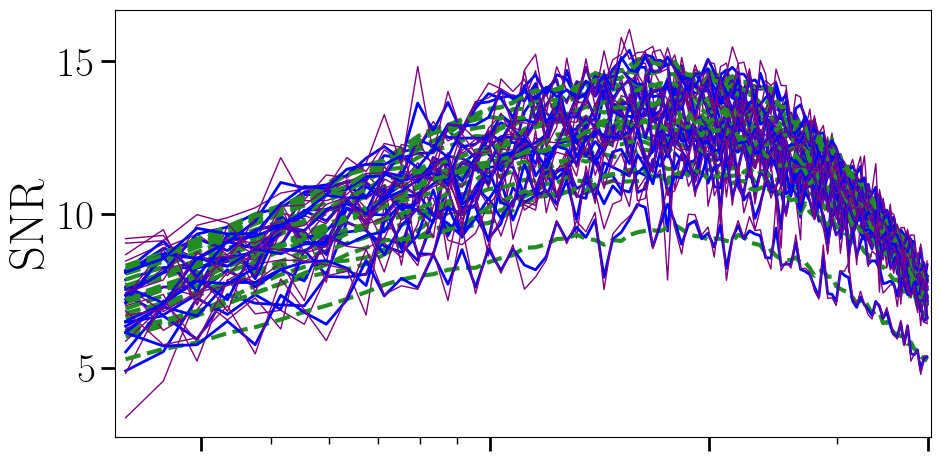

In [24]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
i = 1  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'forestgreen' , 'ec':'green'       , 'lw':3, 'ls':'dashed', 'label':'theory'    , 'alpha':0.2 , },
              'sim':{'c':'blue'        , 'ec':'dodgerblue'  , 'lw':2, 'ls':'solid' , 'label':'simulated' , 'alpha':0.4 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':1, 'ls':'dashed', 'label':'estimated' , 'alpha':0.7 , },
              'bft':{'c':'firebrick'   , 'ec':'crimson'     , 'lw':2, 'ls':'solid', 'label':'best-fit'  , 'alpha':0.7 , },              
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
for i in range(19):
    ax.plot(llx_data,    dt_thr['fixed']['cl'][i,:]/dt_thr['fixed']['el'][i,:],  c=c_settings['thr']['c'], lw=c_settings['thr']['lw'], ls=c_settings['thr']['ls'])#, label='theory' )
    ax.plot(llx_data,    dt_sim['fixed']['cl'][i,:]/dt_sim['fixed']['el'][i,:],  c=c_settings['sim']['c'], lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#label='simulated' )
    ax.plot(llx_data,    dt_est['fixed']['cl'][i,:]/dt_est['fixed']['el'][i,:],  c=c_settings['est']['c'], lw=c_settings['est']['lw'], ls=c_settings['sim']['ls'])#label='simulated' )


ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
ax.set_xlim([30.5, 405])
#ax.set_ylim(3e-7,1e-4)    
ax.set_yscale('linear'); ax.set_xscale('log')
cxticks = [40, 100, 200, 400]
clxticks = [r'', r'', r'', r'']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.set_ylabel(r'${\rm SNR}$', fontsize=35); #ax.set_xlabel(r'$\ell$', fontsize=35)
###########################################################
plt.show()

399.5 0.44 984.665 18 29
/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_z044freq984_g18hi29__4paper__V1.png


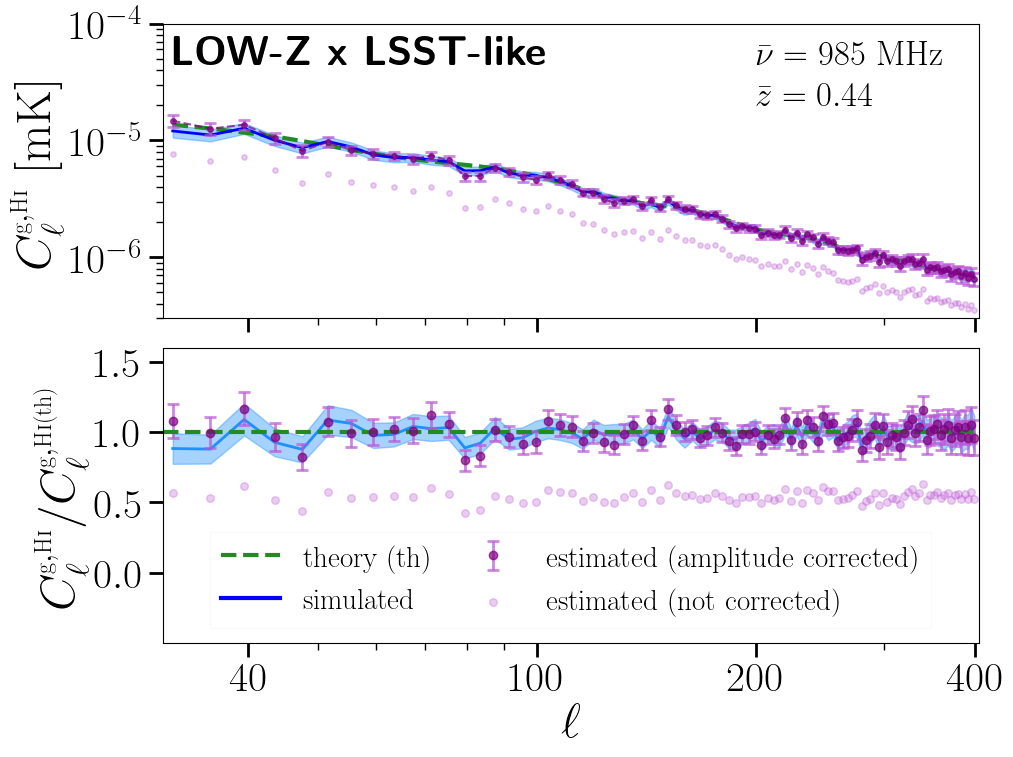

In [29]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(2,1,top=1*1.4,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
i = 18  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'forestgreen' , 'ec':'green'       , 'lw':3, 'ls':'dashed', 'label':'theory'    , 'alpha':0.2 , },
              'sim':{'c':'blue'        , 'ec':'dodgerblue'  , 'lw':2, 'ls':'solid' , 'label':'simulated' , 'alpha':0.4 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':1, 'ls':'dashed', 'label':'estimated' , 'alpha':0.7 , },
              'bft':{'c':'firebrick'   , 'ec':'crimson'     , 'lw':2, 'ls':'solid', 'label':'best-fit'  , 'alpha':0.7 , },              
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
ax.plot(llx_data,    dt_thr['fixed']['cl'][i,:],  c=c_settings['thr']['c'], lw=c_settings['thr']['lw'], ls=c_settings['thr']['ls'])#, label='theory' )
ax.plot(llx_data,    dt_sim['fixed']['cl'][i,:],  c=c_settings['sim']['c'], lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#label='simulated' )
plt.fill_between(llx_data, dt_sim['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:], 
                           dt_sim['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:], 
                 alpha=c_settings['sim']['alpha'], color=c_settings['sim']['ec'], interpolate=True)
ax.errorbar(llx_data,dt_est['fixed']['cl'][i,:], dt_est['fixed']['el'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'], ls=c_settings['est']['ls'],
            elinewidth=2, capsize=4, capthick=2, markersize=4, 
            alpha=c_settings['est']['alpha'], label=c_settings['est']['label'])

ax.scatter(llx_data, dt_est['nfixed']['cl'][i,:], #dt_est['nfixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
           color=c_settings['est']['ec'],  alpha=c_settings['est']['alpha']-0.4, s=15)
### HERE - start
#ax.plot(llx_data,    cl_th[i,:],  c=c_settings['bft']['c'], lw=c_settings['bft']['lw'], ls=c_settings['bft']['ls'])#label='simulated' )
### HERE - end
# x-axis
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
#
ax.set_xlim([30.5, 405])
ax.set_ylim(3e-7,1e-4)    
ax.set_yscale('log'); ax.set_xscale('log')
cxticks = [40, 100, 200, 400]
clxticks = [r'', r'', r'', r'']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}\ [\textrm{mK}]$', fontsize=35); #ax.set_xlabel(r'$\ell$', fontsize=35)
##################################################
ax  = plt.subplot(grid[1,0]) 
ax.plot(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:],  c=c_settings['sim']['ec']  , lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#, label='simulated' )
plt.fill_between(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                           dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                alpha=c_settings['sim']['alpha'], color=c_settings['sim']['ec'], interpolate=True)    

err_est= ax.errorbar(llx_data, dt_est['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], dt_est['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],ls='None',
            elinewidth=2, capsize=4, capthick=2, markersize=6,  alpha=c_settings['est']['alpha'])#, label='(5k-m0)')

sc_label = ax.scatter(llx_data, dt_est['nfixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], #dt_est['nfixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
           color=c_settings['est']['ec'],  alpha=c_settings['est']['alpha']-0.4, s=30)
### HERE - start
#ax.plot(llx_data,    cl_th[i,:]/dt_thr['fixed']['cl'][i,:],  c=c_settings['bft']['c'], lw=c_settings['bft']['lw'], ls=c_settings['bft']['ls'])#label='simulated' )
### HERE - end
ax.axhline(y=1,ls=c_settings['thr']['ls'],color=c_settings['thr']['c'],lw=c_settings['thr']['lw'])
ax.set_xscale('log')
ax.tick_params(axis='both', labelsize=30)
ax.set_xlim([30.5, 405])
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\LARGE{\textrm{(th)}}}_{\ell}$', fontsize=35); ax.set_xlabel(r'$\ell$', fontsize=35)
# y-axis
cyticks = [0.0, 0.5, 1.0, 1.5]
ax.set_yticks(cyticks)
# x-axis
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.set_ylim(-0.5,1.6)
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
###########################################################
ax  = plt.subplot(grid[1,0]) 
custom_lines = [Line2D([], [], 
                             color    =c_settings['thr']['c'],
                             linewidth=3,#c_settings['thr']['lw'], 
                             linestyle='dashed'),#c_settings['thr']['ls']),
                Line2D([], [], 
                             color    =c_settings['sim']['c'],
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle=c_settings['sim']['ls']),
                err_est,
                sc_label
               ]
ax.legend(custom_lines, [r'$\textrm{theory (th)}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated (amplitude corrected)}$',
                         r'$\textrm{estimated (not corrected) }$',
                        ], ncols=2,
         fontsize=21, loc='lower center',framealpha=0.1, fancybox=False,
         #handletextpad=0.8, 
         columnspacing=1.1)
###########################################################
ax  = plt.subplot(grid[0,0]) 
ax.text(x=31.5    , y=0.45e-4, s=r'$\textbf{LOW-Z x LSST-like}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 30})
ax.text(x=300-100, y=0.45e-4, s=r'$\bar{\nu} = '+'{:.0f}$'.format(f)+r'$\textrm{ MHz}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
ax.text(x=300-100, y=0.20e-4, s=r'$\bar{z} = '+'{}$'.format(z), 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
print(llx_data.max(), z,f,i,ibin)
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper__V1.png".format("LOWZxLSST", 'cl_cx',"z{}freq{}_g{}hi{}".format(str(np.around(z,decimals=2)).replace(".", ""),int(f),i,ibin))
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

399.5 0.21 1171.335 1 9
/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_z021freq1171_g1hi9__4paper__V4.pdf


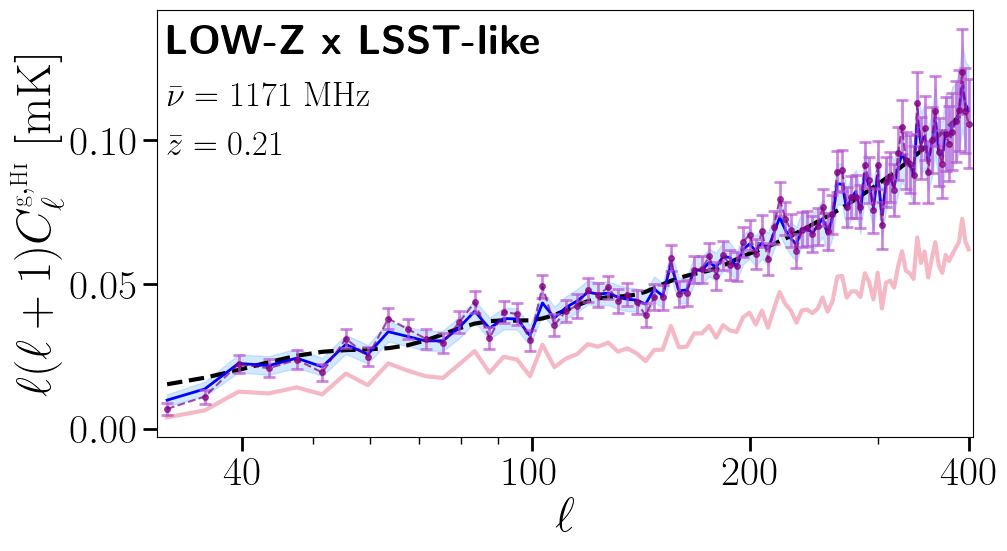

In [426]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
i = 1  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'black'       , 'ec':'black'       , 'lw':3, 'ls':'dashed', 'label':'theory'    , 'alpha':0.5 , },
              'sim':{'c':'blue'        , 'ec':'dodgerblue'  , 'lw':2, 'ls':'solid' , 'label':'simulated' , 'alpha':0.4 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':1, 'ls':'dashed', 'label':'estimated' , 'alpha':0.7 , },
              'bft':{'c':'crimson'     , 'ec':'crimson'     , 'lw':3, 'ls':'solid', 'label':'best-fit'   , 'alpha':0.7 , },              
             }
fact = llx_data*(llx_data+1)
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
ax.plot(llx_data,    fact*dt_thr['fixed']['cl'][i,:],  c=c_settings['thr']['c'], lw=c_settings['thr']['lw'], ls=c_settings['thr']['ls'])#, label='theory' )
plt.fill_between(llx_data, fact*(dt_sim['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:]), 
                           fact*(dt_sim['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:]), 
                 alpha=c_settings['sim']['alpha']-0.2, color=c_settings['sim']['ec'], interpolate=True)
ax.plot(llx_data,    fact*dt_sim['fixed']['cl'][i,:],  c=c_settings['sim']['c'], lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#label='simulated' )
ax.errorbar(llx_data, fact*dt_est['fixed']['cl'][i,:], fact*dt_est['fixed']['el'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'], ls=c_settings['est']['ls'],
            elinewidth=2, capsize=4, capthick=2, markersize=4, 
            alpha=c_settings['est']['alpha'], label=c_settings['est']['label'])

ax.plot(llx_data, fact*dt_est['nfixed']['cl'][i,:],
        color=c_settings['bft']['ec'],  alpha=c_settings['bft']['alpha']-0.4, lw=c_settings['bft']['lw'])#, marker='.')

#ax.scatter(llx_data, dt_est['nfixed']['cl'][i,:],
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
#
#ax.set_ylim(3e-7,0.4e-4)    
ax.set_yscale('linear'); ax.set_xscale('log')
ax.set_xlim([30.5, 405])
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.set_ylabel(r'$\ell(\ell+1)C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}\ [\textrm{mK}]$', fontsize=35); #ax.set_xlabel(r'$\ell$', fontsize=35)
ax.set_xlabel(r'$\ell$', fontsize=35)
###########################################################
ax.text(x=31.5, y=0.13, s=r'$\textbf{LOW-Z x LSST-like}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 30})
ax.text(x=31.5, y=0.112, s=r'$\bar{\nu} = '+'{:.0f}$'.format(f)+r'$\textrm{ MHz}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
ax.text(x=31.5, y=0.095, s=r'$\bar{z} = '+'{}$'.format(z), 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
print(llx_data.max(), z,f,i,ibin)
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper__V4.pdf".format("LOWZxLSST", 'cl_cx',"z{}freq{}_g{}hi{}".format(str(np.around(z,decimals=2)).replace(".", ""),int(f),i,ibin))
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_z021freq1171_g1hi9__4paper__V4__normalized.pdf


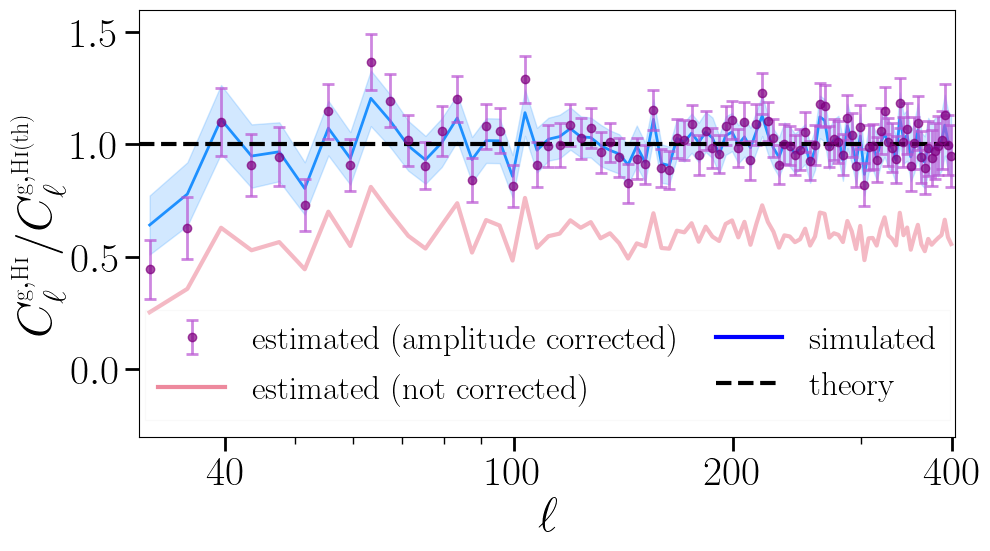

In [427]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
i = 1  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'black'       , 'ec':'black'       , 'lw':3, 'ls':'dashed', 'label':'theory'    , 'alpha':0.5 , },
              'sim':{'c':'blue'        , 'ec':'dodgerblue'  , 'lw':2, 'ls':'solid' , 'label':'simulated' , 'alpha':0.4 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':1, 'ls':'dashed', 'label':'estimated' , 'alpha':0.7 , },
              'bft':{'c':'crimson'   , 'ec':'crimson'       , 'lw':3, 'ls':'solid', 'label':'best-fit'  , 'alpha':0.7 , },              
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
plt.fill_between(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                           dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                alpha=c_settings['sim']['alpha']-0.2, color=c_settings['sim']['ec'], interpolate=True)    
ax.plot(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:],  c=c_settings['sim']['ec']  , lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#, label='simulated' )

err_est= ax.errorbar(llx_data, dt_est['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], dt_est['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],ls='None',
            elinewidth=2, capsize=4, capthick=2, markersize=6,  alpha=c_settings['est']['alpha'])#, label='(5k-m0)')

#sc_label = ax.scatter(llx_data, dt_est['nfixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], #dt_est['nfixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
#           color=c_settings['est']['ec'],  alpha=c_settings['est']['alpha']-0.4, s=30)


sc_label = ax.plot(llx_data, dt_est['nfixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], #dt_est['nfixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
           color=c_settings['bft']['ec'],  alpha=c_settings['bft']['alpha']-0.4, lw=c_settings['bft']['lw'])

ax.axhline(y=1,ls=c_settings['thr']['ls'],color=c_settings['thr']['c'],lw=c_settings['thr']['lw'])
ax.set_xscale('log')
ax.tick_params(axis='both', labelsize=30)
ax.set_xlim([30.5, 405])
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\LARGE{\textrm{(th)}}}_{\ell}$', fontsize=35); 
ax.set_xlabel(r'$\ell$', fontsize=35)
# y-axis
cyticks = [0.0, 0.5, 1.0, 1.5]
ax.set_yticks(cyticks)
# x-axis
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.set_ylim(-0.3,1.6)
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
###########################################################
custom_lines = [err_est,
                Line2D([], [], 
                             color    =c_settings['bft']['c'],
                             linewidth=3,alpha=0.5, 
                             linestyle=c_settings['bft']['ls']),
                Line2D([], [], 
                             color    =c_settings['sim']['c'],
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle=c_settings['sim']['ls']),
                Line2D([], [], 
                             color    =c_settings['thr']['c'],
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle=c_settings['thr']['ls']),                
                
                
               ]
ax.legend(custom_lines, [
                         r'$\textrm{estimated (amplitude corrected)}$',
                         r'$\textrm{estimated (not corrected) }$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{theory}$',    
                        ], ncols=2,
         fontsize=24, loc='lower center',framealpha=0.1, fancybox=False,
         #handletextpad=0.8, 
         columnspacing=1.1)
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper__V4__normalized.pdf".format("LOWZxLSST", 'cl_cx',"z{}freq{}_g{}hi{}".format(str(np.around(z,decimals=2)).replace(".", ""),int(f),i,ibin))
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [59]:
cmap = plt.get_cmap("CMRmap", 25+1)
cmap0 = plt.get_cmap("CMRmap", 25+1)

/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_allspecs__4paper__normalized.png


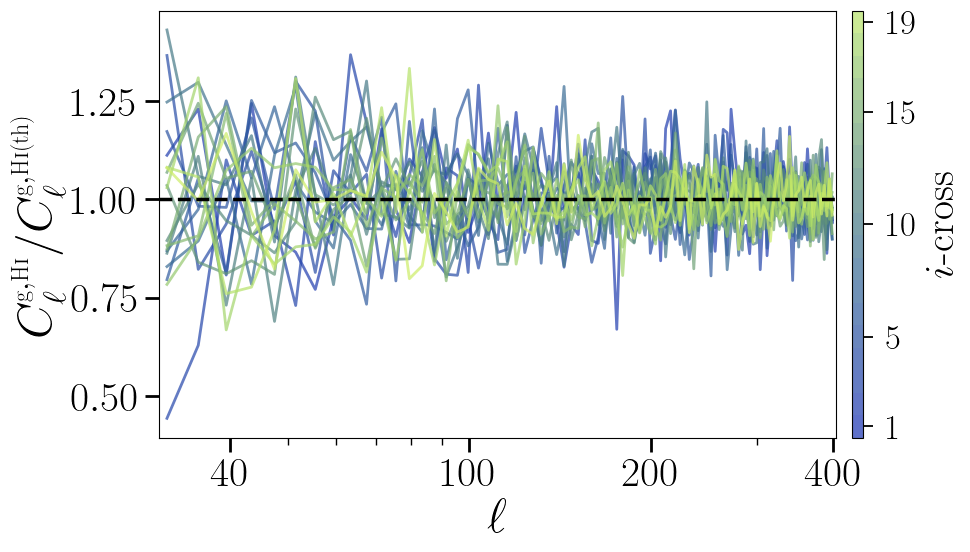

In [109]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
bins = np.arange(19)
n,N  = len(bins),len(bins)
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(0, N+1,1),N)
#cmap = plt.get_cmap("ocean", N+1)
#cmap = plt.get_cmap('viridis', N+3)
cmap = cmc.imola.resampled(N+3) 
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
i = 18  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'forestgreen' , 'ec':'black'       , 'lw':2.5, 'ls':'dashed', 'label':'theory'    , 'alpha':0.2 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':2.0, 'ls':'solid' , 'label':'estimated' , 'alpha':0.7 , },             
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
for i in range(19):
    ax.plot(llx_data, dt_est['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:],  c=cmap(i+1)  , lw=c_settings['est']['lw'], ls=c_settings['est']['ls'], alpha=0.7)#, label='simulated' )
ax.axhline(y=1,ls=c_settings['thr']['ls'],color='black',lw=c_settings['thr']['lw'])
ax.set_xscale('log')
ax.set_xlim([30.5, 405])
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\LARGE{\textrm{(th)}}}_{\ell}$', fontsize=35); ax.set_xlabel(r'$\ell$', fontsize=35)
##################################################
cticks = np.array([0, 4, 9, 14, 18])
ctick_labels = [r'${}$'.format(i) for i in [1, 5, 10, 15, 19]]

cbar = fig.colorbar(sm, ax=ax, pad=0.02, aspect=40, ticks=cticks + 0.5, alpha=0.7)
cbar.set_label(label=r'$i\textrm{-cross}$', size=30)
cbar.ax.set_yticklabels(ctick_labels)
cbar.ax.tick_params(which='major', labelsize=25, pad=10, length=7, width=1.3)
cbar.ax.set_yticks(cticks + 0.5)                          # keep only the 5 centre ticks
cbar.ax.yaxis.set_minor_locator(mpl.ticker.NullLocator()) # remove all minor ticks
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper__normalized.png".format("LOWZxLSST", 'cl_cx',"allspecs")
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [371]:
dt_est['fixed']['cl'].shape

(19, 93)

In [377]:
numz  = 100
gbins = [1,2,3,4,5,6,7]
Whis, zhis = np.zeros((len(gbins),numz)), np.zeros((len(gbins),numz))
for i,gbin in enumerate(gbins):
    w_,z_ = get_Whi_z_bins(hbins=bins_f1f2[gbin], zvec = z_lowz, pars=params, pars_aps=params_APS, numz=numz)
    if not i: 
        Whis = {gbin: dcopy( w_ )}
        zhis = {gbin: dcopy( z_ )}
    else: 
        Whis[gbin] = dcopy( w_ )
        zhis[gbin] = dcopy( z_ )
    del w_,z_

In [380]:
zhis.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7])

In [395]:
zhis[1].shape

(2, 100)

In [409]:
bins = [1,10,19]
ibin = all_bins[bins[0]-1]
print(ibins[ibin], zeff[ibin],feff[ibin])
ibin = all_bins[bins[1]-1]
print(ibins[ibin], zeff[ibin],feff[ibin])
ibin = all_bins[bins[2]-1]
print(ibins[ibin], zeff[ibin],feff[ibin])

8 0.2 1180.665
19 0.32 1078.0
29 0.44 984.665


In [414]:
for i in [1,10,19]:
    i = all_bins[i-1]
    print(ibins[i]+1, zeff[i],feff[i])

9 0.2 1180.665
20 0.32 1078.0
30 0.44 984.665


/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_allspecs__4paper.pdf


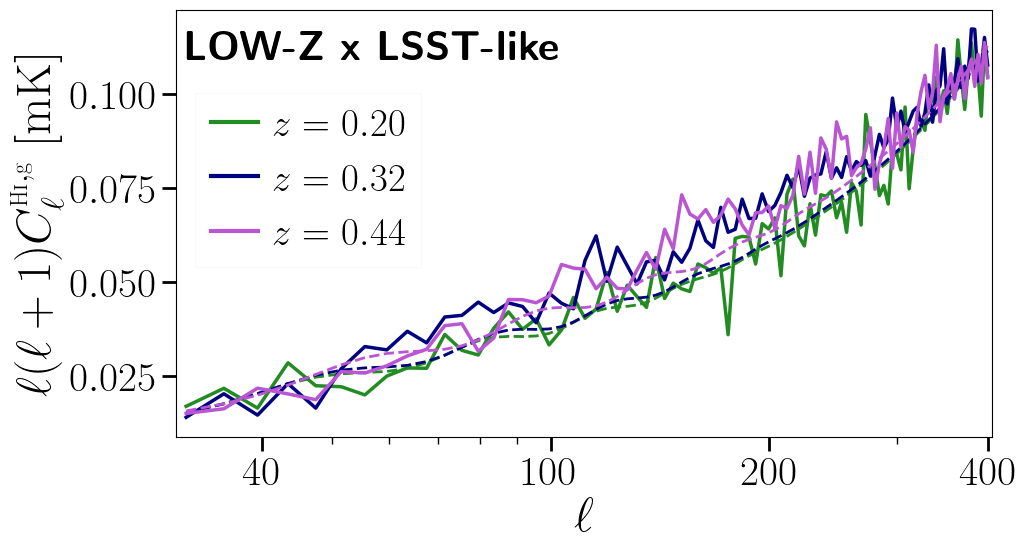

In [431]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
bins = [1,10,19]#np.arange(19)
n,N  = len(bins),len(bins)
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(0, N+1,1),N)
cmap = plt.get_cmap("ocean", 7+1)
cmap0 = plt.get_cmap('Greys', N+1)
#cmap  = cmc.berlin.resampled(N+1) 
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
colors0 = [cmap0(1),cmap0(2),cmap0(3)] 
colors = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange']
#colors = [cmap(0),cmap(3),cmap(5)] 
############################################################
zvec =np.array([])
for ibin in bins:
    ibin = all_bins[ibin-1]
    zvec = np.append(zvec,zeff[ibin])
############################################################
i = 18  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'forestgreen' , 'ec':'green'       , 'lw':2.0, 'ls':'dashed', 'label':'theory'    , 'alpha':0.2 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':2.5, 'ls':'solid' , 'label':'estimated' , 'alpha':0.7 , },             
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
fact = llx_data*(llx_data+1)#/2/np.pi
for i,j in enumerate(np.array(bins)-1):#range(19):
    ax.plot(llx_data,    fact*dt_est['fixed']['cl'][j,:],  c=colors[i], lw=c_settings['est']['lw'], ls=c_settings['est']['ls'])#, alpha=0.6)
    ax.plot(llx_data,    fact*dt_thr['fixed']['cl'][i,:],  c=colors[i], lw=c_settings['thr']['lw'], ls=c_settings['thr']['ls'])
    #ax.plot(llx_data,    dt_est['fixed']['cl'][j,:],  c=colors[i], lw=c_settings['est']['lw'], ls=c_settings['est']['ls'])
ax.set_yscale('linear'); ax.set_xscale('log')
ax.set_xlim([30.5, 405])
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
ax.set_ylabel(r'$\ell(\ell+1)C^{\LARGE{\textrm{H}\textsc{i}},\LARGE{\textrm{g}}}_{\ell}\ [\textrm{mK}]$', fontsize=35); #ax.set_xlabel(r'$\ell$', fontsize=35)
ax.set_xlabel(r'$\ell$', fontsize=35)
###########################################################
custom_lines = [Line2D([], [], 
                             color    =colors[0],
                             linewidth=3,#c_settings['thr']['lw'], 
                             linestyle='solid'),#c_settings['thr']['ls']),
                Line2D([], [], 
                             color    =colors[1],
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle='solid'),
                Line2D([], [], 
                             color    =colors[2],
                             linewidth=3,#c_settings['est']['lw'], 
                             linestyle='solid'),              
               ]
ax.legend(custom_lines, [r'$z = '+ "{:.2f}".format(zvec[0])+"$",
                         r'$z = '+ "{:.2f}".format(zvec[1])+"$",
                         r'$z = '+ "{:.2f}".format(zvec[2])+"$",
                        ] , ncols=1,
         fontsize=28      , loc='upper left' , bbox_to_anchor=(0.0, 0.85),
         framealpha=0.1   , fancybox=False   ,
         handletextpad=0.4, columnspacing=0.5, handlelength=1.2)
###########################################################
ax.text(x=31.5, y=0.109, s=r'$\textbf{LOW-Z x LSST-like}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 30})
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper.pdf".format("LOWZxLSST", 'cl_cx',"allspecs")
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx_allspecs__4paper__normalized.pdf


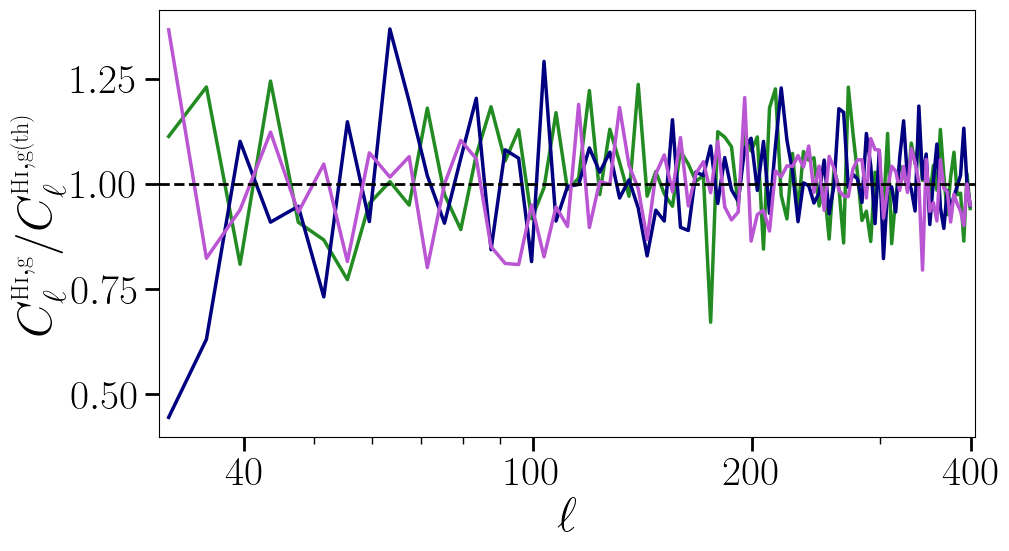

In [430]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*1.0,right=1.4, wspace=0.03, hspace=0.1) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
for i,j in enumerate(np.array(bins)-1):#range(19):
    ax.plot(llx_data, dt_est['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:],  c=colors[i] , lw=c_settings['est']['lw'], ls=c_settings['est']['ls'])#, alpha=0.6)#, label='simulated' )
ax.axhline(y=1,ls=c_settings['thr']['ls'],color='black',lw=c_settings['thr']['lw'])
ax.set_xscale('log')
ax.set_xlim([30.5, 405])
cxticks = [40, 100, 200, 400]
clxticks = [r'$40$', r'$100$', r'$200$', r'$400$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)#
ax.tick_params(which='major', width=2, length=10)
ax.tick_params(which='minor', width=1, length=5)
ax.set_ylabel(r'$C^{\LARGE{\textrm{H}\textsc{i}},\LARGE{\textrm{g}}}_{\ell}/C^{\LARGE{\textrm{H}\textsc{i},\LARGE{\textrm{g}}}\LARGE{\textrm{(th)}}}_{\ell}$', fontsize=35); ax.set_xlabel(r'$\ell$', fontsize=35)
##################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}__4paper__normalized.pdf".format("LOWZxLSST", 'cl_cx',"allspecs")
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

## -------------

In [ ]:
#type_data = 'estimated'
nperc     = '100'
nsims_tag = '500sims'
bins_f1   = None
bins_f2  = np.array([1,2,3,4,5,6,7])#np.array(BINS_CX)#[1,2,3,4,5,6,7])
#bins_f2   = np.array([1])
data_dim  = [30,768]
#COV_model = 3 #[ see above ]
########################################################################################
path_dir = '/data/AMARINS/LSSxHI-DATA/forecast/input/'
file_yaml = 'generating_APS_theory_{b}x{c}.yaml'.format(b=4,c=18) 
filename_cl_yaml = os.path.join(path_dir,file_yaml)
p_loaded     = c4ft.load_yaml_fileformat(filename_cl_yaml, verbose=0)
params_APS   = dcopy(p_loaded["APS"])
params_cosmo = dcopy(p_loaded["cosmology"]) 
del p_loaded
################################
dt_dict = get_data(g_bins=bins_f2, filter_ell=WAEL, ndim=data_dim, 
                   path_to_tf  ='/data/AMARINS/LSSxHI-DATA/tfunction/LSST_40_0001__{}'.format(nsims_tag),
                   #path_to_data='/Users/alessandromarins/Programmation/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed'.format(nperc),
                   path_to_data='/data/AMARINS/LSSxHI-CODES/forecast/input/hi_error_{}_tffixed/hi_{}'.format(nperc, nsims_tag),
                   type_of_data=type_data
                  )
__Clx_data__    = dt_dict['fixed']['cl']
__errClx_data__ = dt_dict['fixed']['el']
bins_f1f2   = dt_dict['bins_f1f2_all']
################################
params_APS['field_1_params']['bins_to_use']= {'f1f2': None } #bins_f1 } <--will be select afterwards. Just creating the dict keyword
params_APS['field_2_params']['bins_to_use']= {'f1f2': bins_f2} 
params_APS['field_12_params'] = {'bins_to_use': bins_f1f2} 
params_APS['field_12_params']['cl-size']  = int(__Clx_data__.shape[1])#clx_data[WDEL].size)
params_APS['field_12_params']['ncl-size'] = int(__Clx_data__.shape[0])#Clx_data.shape[0]/clx_data[WDEL].shape[0])
__Clx_data__    = __Clx_data__.flatten()
__errClx_data__ = __errClx_data__.flatten()
#######################################################################################

In [391]:
###################################################################
timei       = time.time()
USE_CX = True
AMPL_FITTING_CX = False
NUM_Z  = 100
params_cosmo['H0'     ] = 67.4
params_cosmo['ombh2'  ] = 0.022
params_cosmo['omch2'  ] = 0.122
params_cosmo['mnu'    ] = 0.06
params_cosmo['As'     ] = 2.0e-9
params_cosmo['ns'     ] = 0.965
params_cosmo['z'      ] = np.logspace(np.log10(1e-5),np.log10(5), 256)
params_cosmo['kmax'   ] = 100
params_cosmo['minkh'  ] = 1e-5
params_cosmo['maxkh'  ] = 100
params_cosmo['npoints'] = 1000000
params_cosmo['DE_model'       ] = 'DarkEnergyPPF'
params_cosmo['Pk_nonlinear'   ] = True
params_cosmo['halofit_version'] = 'takahashi'
WSEL = (leff>LMIN)&(leff<LMAX)
params_APS["namaster"] = {"b":b, "leff": leff, "lbinner": b.bin_cell}

params_cosmo['w0'] = -1.12
params_cosmo['wa'] = -0.23
params_camb = c4ft.get_camb_results(params_cosmo)
###################################################################
timef = dcopy( time.time() - timei )
print('\n------------------------------------------')
print('running time: {} min'.format( np.around(timef/60,decimals=2)))
print('------------------------------------------\n')


------------------------------------------
running time: 0.04 min
------------------------------------------



In [392]:
cl_data = dcopy( __Clx_data__) 

In [393]:
###################################################################
timei       = time.time()
#####################################
lsize = params_APS['field_12_params']['cl-size'] #number of ells
ncl   = params_APS['field_12_params']['ncl-size']#number of channels
zf1   = params_APS["field_1_params"]["z"]
cl_eff = np.array([])
cl_data_new = cl_data.reshape(ncl, lsize)#.T
bins_f1f2   = dcopy( params_APS['field_12_params']['bins_to_use'] ) #<-- all possibles
bins_f2     = dcopy( params_APS['field_2_params']['bins_to_use']['f1f2'] )
for g, g_index in enumerate(bins_f2):
    cl_th      = np.zeros(( params_APS["field_1_params"]["nbands"], 3*NSIDE )) 
    bins_f1_cx = bins_f1f2[ params_APS['field_2_params']['bins_to_use']['f1f2'][g] ]
    #bins_f1    = np.arange(params_APS["field_1_params"]["nbands"] ) if amplitude_correction else bins_f1_cx
    bins_f1    = bins_f1_cx
    #print('g: ', g_index )
    for h_index in bins_f1:
        params_APS['field_1_params']['bin_to_use'] = h_index
        params_APS['field_2_params']['bin_to_use'] = g_index                
        zmin = max(zf1[h_index : h_index + 2].min(), params_APS["field_2_params"]["z_min"])
        zmax = min(zf1[h_index : h_index + 2].max(), params_APS["field_2_params"]["z_max"])  
        zv   = np.logspace(np.log10(zmin), np.log10(zmax), NUM_Z) 
        _, clth = c4ft.get_cx_theory(zv, params_camb, params_APS,  kind_integ='quad', quad_limit=5000)        
        ###
        index_0 = np.where((clth<EPS)*(clth>-EPS))
        clth[index_0]=0    
        ###                
        if ( h_index>max(bins_f1_cx) ) and ( clth[index_0].size/clth.size>0.3 ) and speedup:
            break
        else:
            cl_th[h_index,:] = dcopy(clth)# if not h_index else np.vstack(( cl_th,  dcopy(clth) ))
            if h_index in bins_f1_cx:
                cl_eff = np.hstack(( cl_eff, params_APS["namaster"]["lbinner"](clth)[WSEL] ))        
#####################################
timef = dcopy( time.time() - timei )
print('\n------------------------------------------')
print('running time: {} min'.format( np.around(timef/60,decimals=2)))
print('------------------------------------------\n')                
###################################################################


------------------------------------------
running time: 0.58 min
------------------------------------------



In [394]:
all_bins = np.hstack([bins_f1f2[j] for j in bins_f1f2.keys() ])
cl_th    = cl_eff.reshape(all_bins.size,-1)

399.5 0.21 1171.335 1 9
/data/AMARINS/LSSxHI-CODES/images/LOWZxLSST_cl_cx__z021freq1171_g1hi9_V2.png


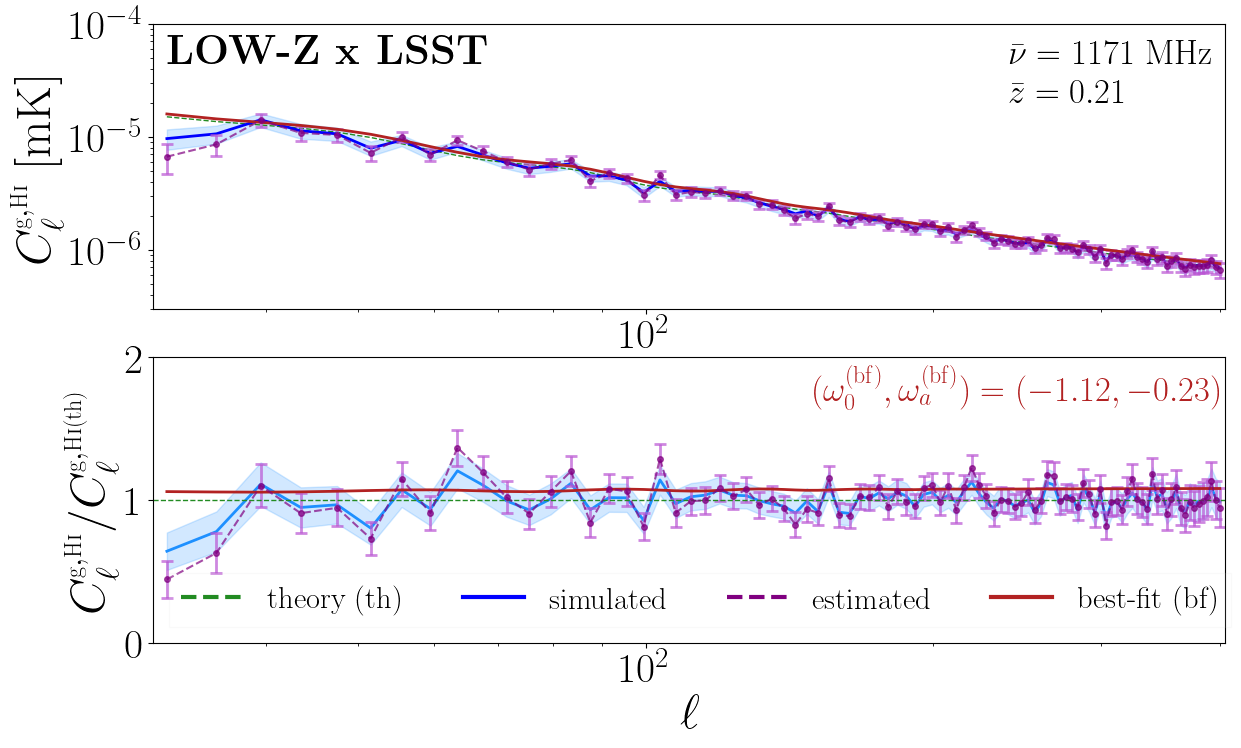

In [395]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(2,1,top=1*1.4,right=1.8, wspace=0.03, hspace=0.17) ################################################
########################################################################################################################
i = 1  #4,8
ibin = all_bins[i]
_,z,f  = ibins[ibin], zeff[ibin],feff[ibin]
llx_data = leff[WAEL]
dt_est   = dcopy( dt_5k_m3 )
c_settings = {'thr':{'c':'forestgreen' , 'ec':'green'       , 'lw':1, 'ls':'dashed', 'label':'theory'    , 'alpha':0.2 , },
              'sim':{'c':'blue'        , 'ec':'dodgerblue'  , 'lw':2, 'ls':'solid' , 'label':'simulated' , 'alpha':0.2 , },
              'est':{'c':'purple'      , 'ec':'mediumorchid', 'lw':1, 'ls':'dashed', 'label':'estimated' , 'alpha':0.7 , },
              'bft':{'c':'firebrick'   , 'ec':'crimson'     , 'lw':2, 'ls':'solid', 'label':'best-fit'  , 'alpha':0.7 , },              
             }
##################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
ax.plot(llx_data,    dt_thr['fixed']['cl'][i,:],  c=c_settings['thr']['c'], lw=c_settings['thr']['lw'], ls=c_settings['thr']['ls'])#, label='theory' )
ax.plot(llx_data,    dt_sim['fixed']['cl'][i,:],  c=c_settings['sim']['c'], lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#label='simulated' )
plt.fill_between(llx_data, dt_sim['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:], 
                           dt_sim['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:], 
                 alpha=c_settings['sim']['alpha'], color=c_settings['sim']['ec'], interpolate=True)
ax.errorbar(llx_data,dt_est['fixed']['cl'][i,:], dt_est['fixed']['el'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'], ls=c_settings['est']['ls'],
            elinewidth=2, capsize=4, capthick=2, markersize=4, 
            alpha=c_settings['est']['alpha'], label=c_settings['est']['label'])
### HERE - start
ax.plot(llx_data,    cl_th[i,:],  c=c_settings['bft']['c'], lw=c_settings['bft']['lw'], ls=c_settings['bft']['ls'])#label='simulated' )
### HERE - end
ax.set_ylim(3e-7,1e-4)    
ax.set_yscale('log'); ax.set_xscale('log')
ax.tick_params(axis='both', labelsize=30)
ax.set_xlim([30.5, 405])
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}\ [\textrm{mK}]$', fontsize=35); ax.set_xlabel(r'$\ell$', fontsize=35)
##################################################
ax  = plt.subplot(grid[1,0]) 
ax.plot(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:],  c=c_settings['sim']['ec']  , lw=c_settings['sim']['lw'], ls=c_settings['sim']['ls'])#, label='simulated' )
plt.fill_between(llx_data, dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] - 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                           dt_sim['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:] + 1*dt_sim['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
                alpha=c_settings['sim']['alpha'], color=c_settings['sim']['ec'], interpolate=True)    

ax.errorbar(llx_data, dt_est['fixed']['cl'][i,:]/dt_thr['fixed']['cl'][i,:], dt_est['fixed']['el'][i,:]/dt_thr['fixed']['cl'][i,:], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],ls=c_settings['est']['ls'],
            elinewidth=2, capsize=4, capthick=2, markersize=4, 
            alpha=c_settings['est']['alpha'])#, label='(5k-m0)')
### HERE - start
ax.plot(llx_data,    cl_th[i,:]/dt_thr['fixed']['cl'][i,:],  c=c_settings['bft']['c'], lw=c_settings['bft']['lw'], ls=c_settings['bft']['ls'])#label='simulated' )
### HERE - end
ax.axhline(y=1,ls=c_settings['thr']['ls'],color=c_settings['thr']['c'],lw=c_settings['thr']['lw'])
ax.set_xscale('log')
ax.set_ylim(-0,2)
ax.tick_params(axis='both', labelsize=30)
ax.set_xlim([30.5, 405])
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\LARGE{\textrm{(th)}}}_{\ell}$', fontsize=35); ax.set_xlabel(r'$\ell$', fontsize=35)
###########################################################
ax  = plt.subplot(grid[1,0]) 
custom_lines = [Line2D([], [], 
                             color    =c_settings['thr']['c'],
                             linewidth=3,#c_settings['thr']['lw'], 
                             linestyle='dashed'),#c_settings['thr']['ls']),
                Line2D([], [], 
                             color    =c_settings['sim']['c'],
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle=c_settings['sim']['ls']),
                Line2D([], [], 
                             color    =c_settings['est']['c'],
                             linewidth=3,#c_settings['est']['lw'], 
                             linestyle=c_settings['est']['ls']),
                Line2D([], [], 
                             color    =c_settings['bft']['c'],
                             linewidth=3,#c_settings['est']['lw'], 
                             linestyle=c_settings['bft']['ls']),                
               ]
ax.legend(custom_lines, [r'$\textrm{theory (th)}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated}$',
                         r'$\textrm{best-fit (bf)}$',
                        ], ncols=4,
         fontsize=22, loc='lower left',framealpha=0.1, fancybox=False)
###########################################################
ax  = plt.subplot(grid[0,0]) 
ax.text(x=31.5    , y=0.45e-4, s=r'$\textbf{LOW-Z x LSST}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 30})
ax.text(x=300-60, y=0.45e-4, s=r'$\bar{\nu} = '+'{:.0f}$'.format(f)+r'$\textrm{ MHz}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
ax.text(x=300-60, y=0.20e-4, s=r'$\bar{z} = '+'{}$'.format(z), 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
print(llx_data.max(), z,f,i,ibin)
ax  = plt.subplot(grid[1,0]) 
ax.text(x=300-150, y=1.7, s=r'$(\omega_{0}^{\LARGE{\textrm{(bf)}}},\omega_{a}^{\LARGE{\textrm{(bf)}}}) = '+'({:.2f},{:.2f})$'.format(params_cosmo['w0'],params_cosmo['wa']), 
        fontdict={'family': 'serif', 'color':  c_settings['bft']['c'],  'weight': 'bold','size': 25})
###########################################################
savefigs=1
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}__{}_V2.png".format("LOWZxLSST", 'cl_cx',"z{}freq{}_g{}hi{}".format(str(np.around(z,decimals=2)).replace(".", ""),int(f),i,ibin))
if savefigs: plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [410]:
# ---------------------------------------------------------
# 1. THEORY Data
# ---------------------------------------------------------
data_theory = {
    'Bin': [1, 2, 3, 4, 5, 6, 7],
    'DoF': [184, 277, 370, 277, 277, 184, 184],
    'chi2_min': [0, 0, 0, 0, 0, 0, 0],
    'chi2_red': [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    'p_value': [1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000],
    # w0 values and errors
    'w0': [-0.99, -0.98, -0.99, -0.98, -0.99, -0.99, -0.99],
    'w0_err_low': [0.20, 0.18, 0.16, 0.15, 0.14, 0.15, 0.13],
    'w0_err_high': [0.20, 0.21, 0.16, 0.15, 0.14, 0.15, 0.13],
    # wa values and errors
    'wa': [-0.04, -0.08, -0.05, -0.07, -0.04, -0.03, -0.02],
    'wa_err_low': [0.52, 0.53, 0.43, 0.39, 0.37, 0.37, 0.33],
    'wa_err_high': [0.52, 0.48, 0.43, 0.39, 0.37, 0.37, 0.33],
}

df_theory = pd.DataFrame(data_theory)

# ---------------------------------------------------------
# 2. SIMULATED Data
# ---------------------------------------------------------
data_simulated = {
    'Bin': [1, 2, 3, 4, 5, 6, 7],
    'DoF': [184, 277, 370, 277, 277, 184, 184],
    'chi2_min': [92, 125, 187, 124, 99, 98, 71],
    'chi2_red': [0.50, 0.45, 0.50, 0.45, 0.36, 0.53, 0.38],
    'p_value': [1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000],
    # w0 values and errors
    'w0': [-1.03, -0.87, -1.01, -0.810, -1.07, -1.14, -1.02],
    'w0_err_low': [0.19, 0.13, 0.16, 0.099, 0.16, 0.15, 0.13],
    'w0_err_high': [0.19, 0.18, 0.16, 0.14, 0.16, 0.13, 0.13],
    # wa values and errors
    'wa': [0.06, -0.33, 0.01, -0.52, 0.15, 0.38, 0.07],
    'wa_err_low': [0.51, 0.49, 0.41, 0.37, 0.38, 0.30, 0.33],
    'wa_err_high': [0.57, 0.37, 0.41, 0.27, 0.44, 0.38, 0.33],
}

df_simulated = pd.DataFrame(data_simulated)

# ---------------------------------------------------------
# 3. ESTIMATED Data
# ---------------------------------------------------------
data_estimated = {
    'Bin': [1, 2, 3, 4, 5, 6, 7],
    'DoF': [184, 277, 370, 277, 277, 184, 184],
    'chi2_min': [224, 256, 276, 169, 145, 147, 157],
    'chi2_red': [1.22, 0.93, 0.75, 0.61, 0.52, 0.80, 0.85],
    'p_value': [0.0241, 0.809, 1.000, 1.000, 1.000, 0.978, 0.929],
    # w0 values and errors
    'w0': [-1.11, -0.88, -0.98, -0.809, -1.14, -1.17, -0.95],
    'w0_err_low': [0.22, 0.13, 0.15, 0.099, 0.17, 0.15, 0.12],
    'w0_err_high': [0.17, 0.18, 0.15, 0.14, 0.14, 0.12, 0.12],
    # wa values and errors
    'wa': [0.22, -0.36, -0.095, -0.51, 0.34, 0.47, -0.14],
    'wa_err_low': [0.44, 0.48, 0.40, 0.37, 0.33, 0.27, 0.31],
    'wa_err_high': [0.59, 0.35, 0.40, 0.27, 0.43, 0.36, 0.31],
}

# Create DataFrame
df_theory    = pd.DataFrame(data_theory)
df_simulated = pd.DataFrame(data_simulated)
df_estimated = pd.DataFrame(data_estimated)

In [411]:
N,nch = 30, 30
dinfo = cxft.get_zeff(numin =980, numax =1260, nbands= nch, n_curves=N)
feff  = dinfo['nu_eff']
zeff  = dinfo['zeff']
ibins = dinfo['bins']
bins_f1f2 = {1: np.array([8,9        ]),
             2: np.array([12,13,14   ]),        
             3: np.array([15,16,17,18]),
             4: np.array([19,20,21   ]),
             5: np.array([22,23,24   ]),
             6: np.array([25,26      ]),
             7: np.array([28,29      ])    
             }
all_bins = np.hstack([bins_f1f2[j] for j in bins_f1f2.keys() ])

In [412]:
zm_vec = np.zeros(len(bins_f1f2.keys()))
fm_vec = np.zeros(len(bins_f1f2.keys()))
for i,iset in enumerate(bins_f1f2.keys()):
    zm=0; ncx=0; fm=0
    for icx in bins_f1f2[iset]:
        ncx+=1
        zm+=zeff[icx]
        fm+=feff[icx]
    zm_vec[i]=zm/ncx
    fm_vec[i]=fm/ncx
zm_vec = np.around(zm_vec, decimals=2)
fm_vec = np.around(fm_vec, decimals=0)

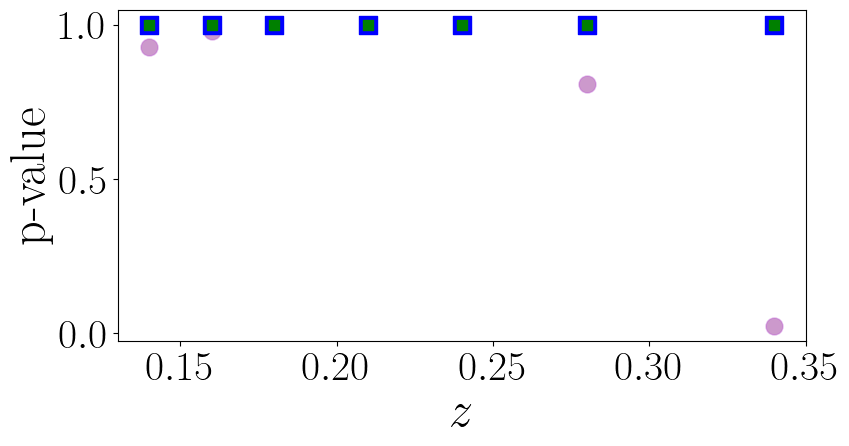

In [413]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.8,right=1.2, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
######
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
zm_plot = np.flip(zm_vec)
pvalue = np.flip( df_["p_value"].to_numpy(dtype=float) )
ax.scatter(zm_plot, pvalue, marker="o", c=c_settings['est']['c'], edgecolors=c_settings['est']['ec'], 
           s=150, alpha=0.4)
#####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
pvalue = np.flip( df_["p_value"].to_numpy(dtype=float) )
ax.scatter(zm_plot, pvalue, marker="s", c=c_settings['sim']['c'], s=150, alpha=1.0)
#####
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
pvalue = np.flip( df_["p_value"].to_numpy(dtype=float) )
ax.scatter(zm_plot, pvalue, marker="s", c=c_settings['thr']['ec'], s=50, alpha=1.0)
#####
ax.set_ylabel(r'$\textrm{p-value}$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)
##################################################
plt.show()

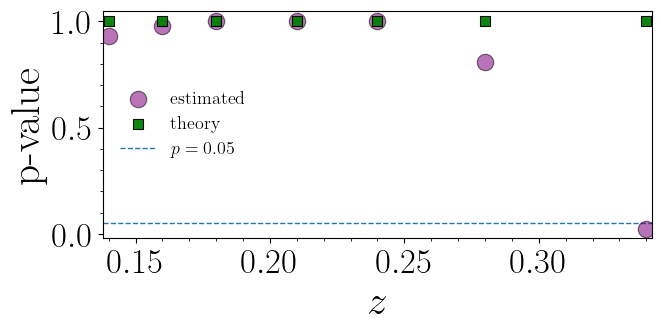

In [414]:
import numpy as np
import matplotlib.pyplot as plt

use_minus_log10p = False   # set True if you prefer -log10(p)

# --- Build consistent ordering (by Bin), and align z accordingly ---
df_est = df_estimated.sort_values("Bin").reset_index(drop=True)
df_thr = df_theory.sort_values("Bin").reset_index(drop=True)

zm_plot = np.asarray(zm_vec)
# If your zm_vec is in reverse order relative to Bin ordering, uncomment:
# zm_plot = zm_plot[::-1]

p_est = df_est["p_value"].to_numpy(dtype=float)
p_thr = df_thr["p_value"].to_numpy(dtype=float)
# If your p-values were previously flipped to match zm_vec, uncomment:
# p_est = p_est[::-1]
# p_thr = p_thr[::-1]

# --- Transform if desired ---
if use_minus_log10p:
    eps = 1e-300
    y_est = -np.log10(np.clip(p_est, eps, 1.0))
    y_thr = -np.log10(np.clip(p_thr, eps, 1.0))
    ylabel = r'$-\log_{10}(p)$'
    ref_lines = [0.05, 0.01]
    ref_y = [-np.log10(v) for v in ref_lines]
else:
    y_est, y_thr = p_est, p_thr
    ylabel = r'$\textrm{p-value}$'
    ref_lines = [0.05, 0.01]
    ref_y = ref_lines

# --- Figure / layout (clean, no manual GridSpec hacks) ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), constrained_layout=True)

# --- Scatter styling: comparable weight, clean edges, correct z-order ---
ax.scatter(
    zm_plot, y_est,
    marker="o", s=140,
    facecolors=c_settings['est']['c'],
    edgecolors="k", linewidths=0.8,
    alpha=0.55, zorder=2,
    label="estimated"
)

ax.scatter(
    zm_plot, y_thr,
    marker="s", s=50,
    facecolors=c_settings['thr']['ec'],
    edgecolors="k", linewidths=0.8,
    alpha=0.95, zorder=3,
    label="theory"
)

# --- Reference lines (common thresholds) ---
ax.axhline(ref_y[0], linestyle="--", linewidth=1.0, zorder=1, label=r"$p=0.05$")
#ax.axhline(ref_y[1], linestyle=":",  linewidth=1.0, zorder=1, label=r"$p=0.01$")

# --- Axes labels / limits ---
ax.set_xlabel(r"$z$", fontsize=30)
ax.set_ylabel(ylabel, fontsize=30)

# y-limits that make sense for each mode
if use_minus_log10p:
    # give a bit of headroom
    ymax = max(np.nanmax(y_est), np.nanmax(y_thr), ref_y[0]) * 1.10
    ax.set_ylim(0.0, ymax)
else:
    ax.set_ylim(-0.02, 1.05)

# x-limits with small padding
xmin, xmax = np.min(zm_plot), np.max(zm_plot)
ax.set_xlim(xmin - 0.01*(xmax - xmin), xmax + 0.01*(xmax - xmin))

# --- Ticks / grid (science-style readability) ---
ax.tick_params(axis="both", which="major", labelsize=25)
ax.minorticks_on()
#ax.grid(True, which="major", linewidth=0.6, alpha=0.4)
#ax.grid(True, which="minor", linewidth=0.4, alpha=0.2)

# --- Legend ---
ax.legend(frameon=False, fontsize=13, loc="center left")

plt.show()

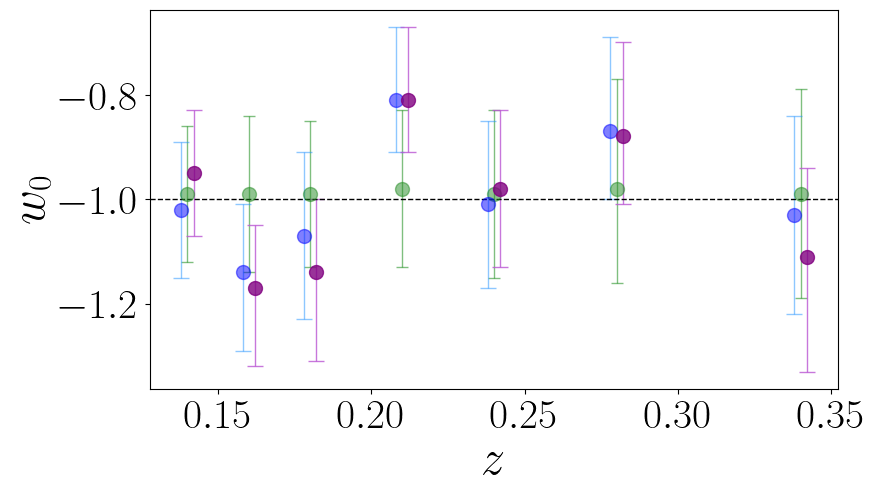

In [415]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.2, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)

####
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
            elinewidth=1, capsize=4, capthick=1, markersize=10, alpha=0.5,
            linewidth=0.6           
            )

####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot-0.002, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
            elinewidth=1, capsize=6, capthick=1, markersize=10, alpha=0.5,
            linewidth=0.6
            )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot+0.002, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
            elinewidth=1, capsize=6, capthick=1, markersize=10, alpha=0.8,
            linewidth=0.6
            )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_0$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=-1,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
#ax.legend(loc='best', framealpha=0, ncols=2)#, bbox_to_anchor=(0.21, 1.2))
##################################################
plt.show()

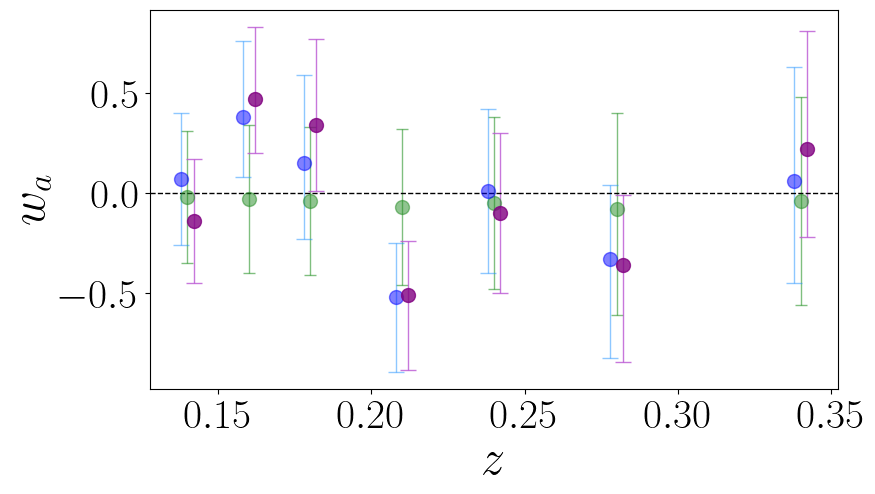

In [416]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.2, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)

####
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
            elinewidth=1, capsize=4, capthick=1, markersize=10, alpha=0.5,
            linewidth=0.6           
            )
####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot-0.002, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
            elinewidth=1, capsize=6, capthick=1, markersize=10, alpha=0.5,
            linewidth=0.6
            )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
ax.errorbar(zm_plot+0.002, wi, [wi_m,wi_p], 
            fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
            elinewidth=1, capsize=6, capthick=1, markersize=10, alpha=0.8,
            linewidth=0.6
            )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_a$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=0,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
#ax.legend(loc='best', framealpha=0, ncols=2)#, bbox_to_anchor=(0.21, 1.2))
##################################################
plt.show()

In [417]:
import pandas as pd
data = [
    {
        "DoF": 1765,
        "chi2_min": 0,
        "chi2_red": 0.00,
        "p_value": 1.00,
        "w0": -0.997,
        "w0_err_low": 0.062,
        "w0_err_high": 0.062,
        "wa": -0.01,
        "wa_err_low": 0.16,
        "wa_err_high": 0.16
    },
    {
        "DoF": 1765,
        "chi2_min": 803,
        "chi2_red": 0.45,
        "p_value": 1.00,
        "w0": -1.012,
        "w0_err_low": 0.066,
        "w0_err_high": 0.066,
        "wa": 0.03,
        "wa_err_low": 0.17,
        "wa_err_high": 0.17
    },
    {
        "DoF": 1765,
        "chi2_min": 1386,
        "chi2_red": 0.79,
        "p_value": 1.00,
        "w0": -1.025,
        "w0_err_low": 0.064,
        "w0_err_high": 0.064,
        "wa": 0.05,
        "wa_err_low": 0.17,
        "wa_err_high": 0.17
    }
]

# Create DataFrame
df_results = pd.DataFrame(data, index=['theory', 'simulated', 'estimated'])

/data/AMARINS/LSSxHI-CODES/images/w0_cross_setbestfit_4paper.png


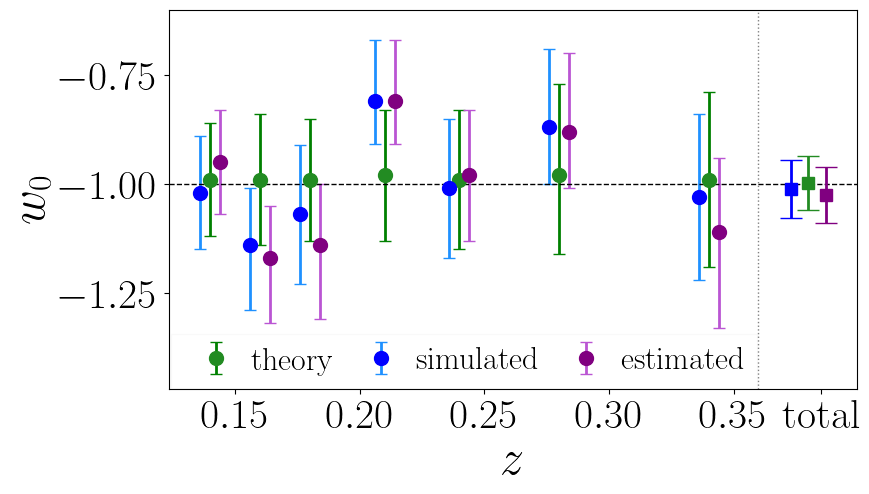

In [511]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.2, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)

####
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_thr = ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'           
                      )
####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_sim = ax.errorbar(zm_plot-0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                       )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_est = ax.errorbar(zm_plot+0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                      )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_0$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=-1,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
##################################################
center  =  0.38
total_x = center
total_y = df_results.loc['theory', 'w0']
err_low = df_results.loc['theory', 'w0_err_low'] 
err_high = df_results.loc['theory', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
                    fmt='s', color=c_settings['thr']['c'], ecolor=c_settings['thr']['c'], 
                    markersize=8, capsize=8, elinewidth=2)
#####
total_x  = center-0.007
total_y  = df_results.loc['simulated', 'w0']
err_low  = df_results.loc['simulated', 'w0_err_low'] 
err_high = df_results.loc['simulated', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['sim']['c'], ecolor=c_settings['sim']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#####
total_x = center+0.007
total_y = df_results.loc['estimated', 'w0']
err_low = df_results.loc['estimated', 'w0_err_low'] 
err_high = df_results.loc['estimated', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['est']['c'], ecolor=c_settings['est']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#######
# y-axis
cyticks = [-1.0,-0.5,0.0,0.5,1.0]#,3.0]
#ax.set_yticks(cyticks)
# x-axis
cxticks = [0.15, 0.20, 0.25, 0.30, 0.35, center+0.005]
clxticks = [r'$0.15$', r'$0.20$', r'$0.25$', r'$0.30$', r'$0.35$', r'$\mathrm{total}$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)
#
ax.axvline(x=0.36, color='gray', linestyle=':', linewidth=1)
ax.set_ylim(-1.47,-0.6)
###########################################################
ax  = plt.subplot(grid[0,0]) 
custom_lines = [err_thr, err_sim,err_est,  
               ]
ax.legend(custom_lines, [r'$\textrm{theory}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated}$',
                        ], ncols=3,
         fontsize=23, loc='lower left',bbox_to_anchor=(-0.02, -0.04),
         framealpha=0.1, fancybox=False,
         handletextpad=0.1, columnspacing=0.5)#, handlelength=1.8)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( 'w0',"cross", 'bestfit', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

/data/AMARINS/LSSxHI-CODES/images/wa_cross_setbestfit_4paper.png


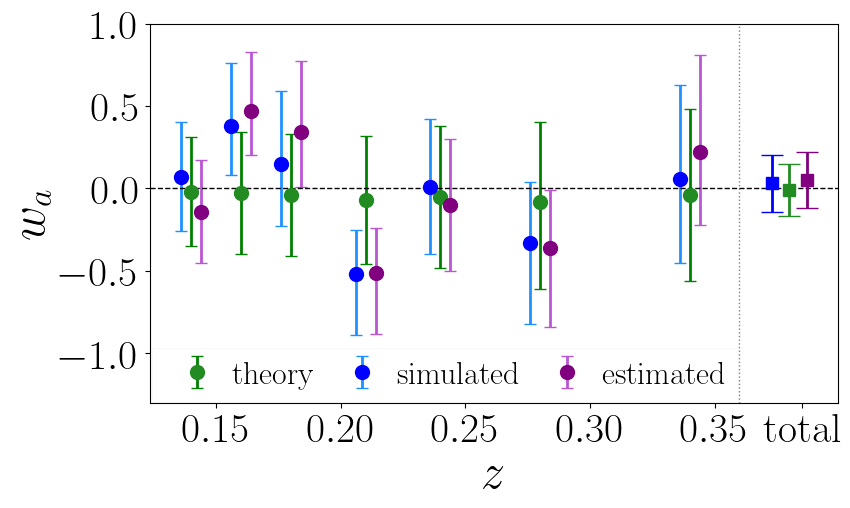

In [509]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.2, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)

####
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_thr = ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'           
                      )
####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_sim = ax.errorbar(zm_plot-0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                       )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_est = ax.errorbar(zm_plot+0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                      )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_a$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=0,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
##################################################
center  =  0.38
total_x = center
total_y = df_results.loc['theory', 'wa']
err_low = df_results.loc['theory', 'wa_err_low'] 
err_high = df_results.loc['theory', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
                    fmt='s', color=c_settings['thr']['c'], ecolor=c_settings['thr']['c'], 
                    markersize=8, capsize=8, elinewidth=2)
#####
total_x  = center-0.007
total_y  = df_results.loc['simulated', 'wa']
err_low  = df_results.loc['simulated', 'wa_err_low'] 
err_high = df_results.loc['simulated', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['sim']['c'], ecolor=c_settings['sim']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#####
total_x = center+0.007
total_y = df_results.loc['estimated', 'wa']
err_low = df_results.loc['estimated', 'wa_err_low'] 
err_high = df_results.loc['estimated', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['est']['c'], ecolor=c_settings['est']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#######
# y-axis
cyticks = [-1.0,-0.5,0.0,0.5,1.0]#,3.0]
ax.set_yticks(cyticks)
# x-axis
cxticks = [0.15, 0.20, 0.25, 0.30, 0.35, center+0.005]
clxticks = [r'$0.15$', r'$0.20$', r'$0.25$', r'$0.30$', r'$0.35$', r'$\mathrm{total}$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)
#
ax.axvline(x=0.36, color='gray', linestyle=':', linewidth=1)
ax.set_ylim(-1.3,1)
###########################################################
ax  = plt.subplot(grid[0,0]) 
custom_lines = [err_thr, err_sim,err_est,  
               ]
ax.legend(custom_lines, [r'$\textrm{theory}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated}$',
                        ], ncols=3,
         fontsize=23, loc='lower left',bbox_to_anchor=(-0.02, -0.04),
         framealpha=0.1, fancybox=False,
         handletextpad=0.1, columnspacing=0.5)#, handlelength=1.8)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( 'wa',"cross", 'bestfit', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [219]:
def get_Whi_z_bin(zmin=None, zmax = None, pars=None, pars_aps=None, numz=100):
    ###########################################
    pars_camb = c4ft.get_camb_results(pars)
    zv   = np.logspace(np.log10(zmin), np.log10(zmax), numz)                
    Whi = c4ft.kernel_hi_vec(
                    zout=zv, 
                    camb_params = pars_camb["camb_params"], 
                    camb_results= pars_camb["camb_results"],
                    zrange      = pars_aps['field_1_params']['z'], 
                    config_dict = pars_aps["field_1_params"], 
                    replace_inf2nan= True, 
                    use_input      = False,
                    params_interp  = None,             
                    get_interp_function=0
                ) 
    return Whi, zv

def get_Whi_z_bins(hbins=[8,9], zvec = None, pars=None, pars_aps=None, numz=100):
    hbins = np.array(hbins)
    Whi_vec = np.zeros((hbins.size, numz))
    z_vec   = np.zeros((hbins.size, numz))    
    for i,hbin in enumerate(hbins):
        zmin  = zvec[hbin+0]
        zmax  = zvec[hbin+1] 
        Whi_vec[i], z_vec[i] = get_Whi_z_bin(zmin=zmin, zmax = zmax, pars=pars, pars_aps=pars_aps, numz=numz)
    return Whi_vec, z_vec


def plot_filter_texts(ax=None, cmap_=None, ypos=1.12, cweight_1='bold', cweight_2='bold', size1=20, size2=13, add_text_outline2=False, text_outline_lw=3, text_outline_fg='black'):
    if add_text_outline2: import matplotlib.patheffects as pe
    ax.text(x=0.200, y=ypos, s=r'$\mathrm{Set 1}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.245, y=ypos, s=r'$\mathrm{Set 2}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.280, y=ypos, s=r'$\mathrm{Set 3}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.321, y=ypos, s=r'$\mathrm{Set 4}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.355, y=ypos, s=r'$\mathrm{Set 5}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.387, y=ypos, s=r'$\mathrm{Set 6}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.427, y=ypos, s=r'$\mathrm{Set 7}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})                                            

In [558]:
## CAMB
path_dir = '/data/AMARINS//LSSxHI-DATA/forecast/input/'
file_yaml = 'generating_APS_theory_{b}x{c}.yaml'.format(b=4,c=18) 
filename_cl_yaml = os.path.join(path_dir,file_yaml)
p_loaded    = c4ft.load_yaml_fileformat(filename_cl_yaml, verbose=0)
params_APS  = dcopy(p_loaded["APS"])
params      = dcopy(p_loaded["cosmology"]) 
######################################################################
params['H0'     ] = 67.4
params['ombh2'  ] = 0.022
params['omch2'  ] = 0.122
params['mnu'    ] = 0.06
params['w0'     ] = -1
params['wa'     ] = 0
params['As'     ] = 2.0e-9
params['ns'     ] = 0.965
params['z'      ] = np.logspace(np.log10(1e-5),np.log10(5), 256)
params['kmax'   ] = 100
params['minkh'  ] = 1e-5
params['maxkh'  ] = 100
params['npoints'] = 1000000
params['DE_model'       ] = 'DarkEnergyPPF'
params['Pk_nonlinear'   ] = True
params['halofit_version'] = 'takahashi'
######################################################################
cpars = camb.set_params(halofit_version=params['halofit_version'])
cpars.set_cosmology(H0=params['H0'], ombh2=params['ombh2'], omch2=params['omch2'])
cpars.InitPower.set_params(ns=params['ns'])
cpars.set_matter_power(redshifts=params['z'], kmax=params['kmax'], silent=1)
cresults  = camb.get_results(cpars)
pk_interp = camb.get_matter_power_interpolator(cpars, 
                                               nonlinear=params['halofit_version'], hubble_units=False, k_hunit=False, 
                                               kmax=params['kmax'], zmax=params['z'][-1])
print('Done!')

bins_f1f2 = {
                1: np.array([8,9        ]),
                #2: np.array([11,12,13,14]),
                2: np.array([12,13,14]),        
                3: np.array([15,16,17,18]),
                4: np.array([19,20,21   ]),
                5: np.array([22,23,24   ]),
                6: np.array([25,26      ]),
                7: np.array([28,29      ])    
                }

Done!


In [559]:
z_lowz  = cxft.z_hi_survey(hi_survey='LOWZ')
numz  = 100
gbins = [1,2,3,4,5,6,7]
Whis, zhis = np.zeros((len(gbins),numz)), np.zeros((len(gbins),numz))
for i,gbin in enumerate(gbins):
    w_,z_ = get_Whi_z_bins(hbins=bins_f1f2[gbin], zvec = z_lowz, pars=params, pars_aps=params_APS, numz=numz)
    if not i: 
        Whis = {gbin: dcopy( w_ )}
        zhis = {gbin: dcopy( z_ )}
    else: 
        Whis[gbin] = dcopy( w_ )
        zhis[gbin] = dcopy( z_ )
    del w_,z_

/data/AMARINS/LSSxHI-CODES/images/wa_cross_setbestfit_4paper.png


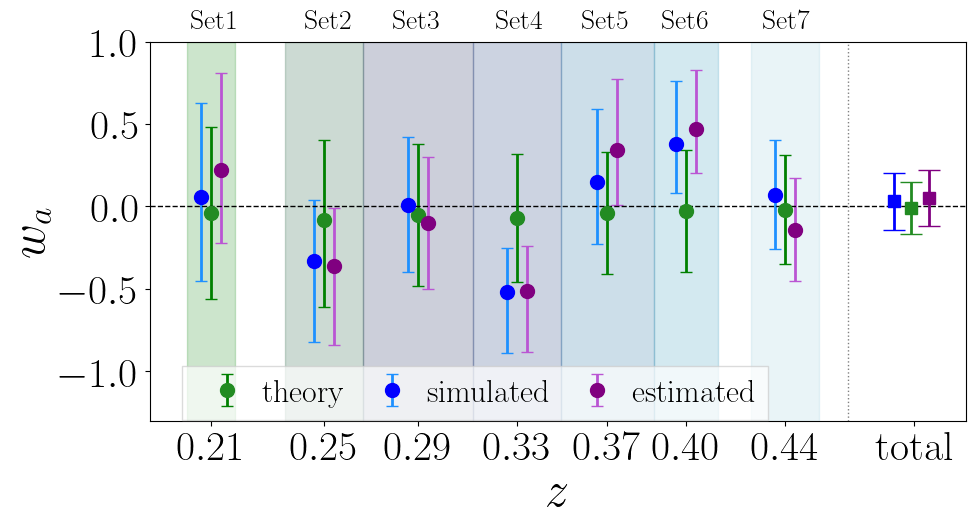

In [650]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.4, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
############################################################
bins = [1,2,3,4,5,6,7]
n,N  = len(bins),len(bins)
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("ocean", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
###########################################################
ax.set_ylim(-1.3,1)
zvec = np.array([])            
for ic,i  in enumerate(bins):#Whis.keys()
    whi = dcopy( Whis[i] )
    zhi = dcopy( zhis[i] )
    for j in range(whi.shape[0]):
        x = zhi[j]
        y = whi[j]
        y=y/y.max()
        #ax.plot(x, y, c=cmap2(i), label=None,lw=2, ls='solid' , alpha=1.00)   
    x = zhi.flatten()
    zvec = np.hstack((zvec,np.array([x.min(), x.max()]) ))
    if ibin==7:
        ax.axvspan(x.min(), x.max(), alpha=0.2, color=cmap(ic))
    else:
        ax.axvspan(x.min(), x.max(), alpha=0.2, color=cmap(ic))

zvec = zvec.reshape(-1,2)      
zvec = np.mean(zvec, axis=1)
center = zvec[-1]+0.05
#######
# y-axis
cyticks = [-1.0,-0.5,0.0,0.5,1.0]#,3.0]
ax.set_yticks(cyticks)
# x-axis
#cxticks = [0.15, 0.20, 0.25, 0.30, 0.35, center+0.005]
cxticks = np.hstack((zvec, center+0.001))
clxticks = [r'${:.2f}$'.format(np.around(i,decimals=2)) for i in zvec]
clxticks = np.hstack([clxticks,r'$\mathrm{total}$'])
#clxticks = [r'$0.15$', r'$0.20$', r'$0.25$', r'$0.30$', r'$0.35$', r'$\mathrm{total}$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)
#
ax.axvline(x=center-0.025, color='gray', linestyle=':', linewidth=1)        
############################################################
zm_vec = dcopy( zvec.flatten() )
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_thr = ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'           
                      )
####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_sim = ax.errorbar(zm_plot-0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                       )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["wa"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["wa_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["wa_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_est = ax.errorbar(zm_plot+0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                      )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_a$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=0,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
##################################################
#center  =  0.38
total_x = center
total_y = df_results.loc['theory', 'wa']
err_low = df_results.loc['theory', 'wa_err_low'] 
err_high = df_results.loc['theory', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
                    fmt='s', color=c_settings['thr']['c'], ecolor=c_settings['thr']['c'], 
                    markersize=8, capsize=8, elinewidth=2)
#####
total_x  = center-0.007
total_y  = df_results.loc['simulated', 'wa']
err_low  = df_results.loc['simulated', 'wa_err_low'] 
err_high = df_results.loc['simulated', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['sim']['c'], ecolor=c_settings['sim']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#####
total_x = center+0.007
total_y = df_results.loc['estimated', 'wa']
err_low = df_results.loc['estimated', 'wa_err_low'] 
err_high = df_results.loc['estimated', 'wa_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['est']['c'], ecolor=c_settings['est']['c'], 
            markersize=8, capsize=8, elinewidth=2)
###########################################################
ax  = plt.subplot(grid[0,0]) 
custom_lines = [err_thr, err_sim,err_est,  
               ]
ax.legend(custom_lines, [r'$\textrm{theory}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated}$',
                        ], ncols=3,
         fontsize=23, loc='lower left',bbox_to_anchor=(+0.02, -0.04),
         framealpha=0.7, fancybox=False,
         handletextpad=0.1, columnspacing=0.5)#, handlelength=1.8)
###########################################################
plot_filter_texts(ax, cmap_=cmap, ypos=1.08, cweight_2='heavy', add_text_outline2=True, text_outline_lw=0.7)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( 'wa',"cross", 'bestfit', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

/data/AMARINS/LSSxHI-CODES/images/w0_cross_setbestfit_4paper.png


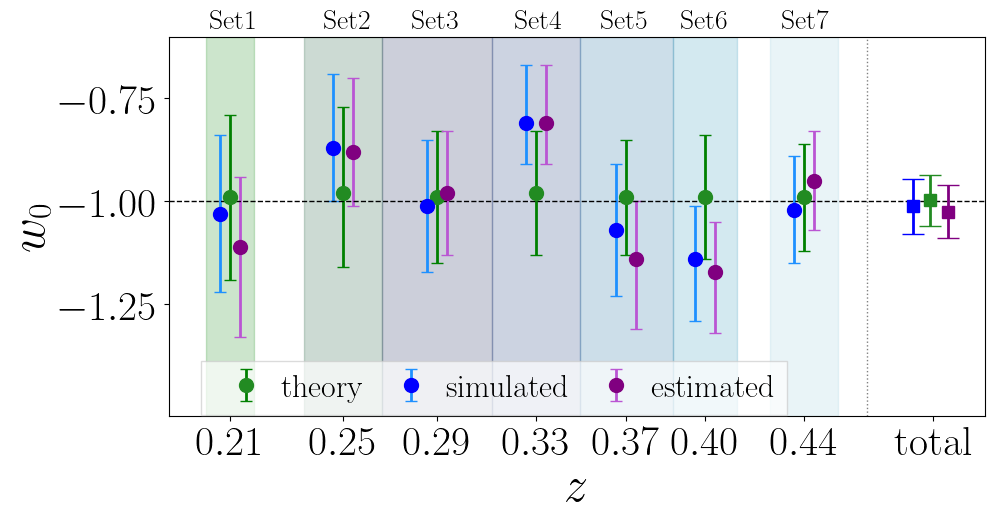

In [651]:
########################################################################################################################
fig   = plt.figure()                                                    ################################################
grid  = plt.GridSpec(1,1,top=1*0.9,right=1.4, wspace=0.03, hspace=0.35) ################################################
########################################################################################################################
ax  = plt.subplot(grid[0,0]) 
ax.tick_params(axis='both', which='major', labelsize=30)
############################################################
bins = [1,2,3,4,5,6,7]
n,N  = len(bins),len(bins)
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("ocean", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
###########################################################
zvec = np.array([])            
for ic,i  in enumerate(bins):#Whis.keys()
    whi = dcopy( Whis[i] )
    zhi = dcopy( zhis[i] )
    for j in range(whi.shape[0]):
        x = zhi[j]
        y = whi[j]
        y=y/y.max()
        #ax.plot(x, y, c=cmap2(i), label=None,lw=2, ls='solid' , alpha=1.00)   
    x = zhi.flatten()
    zvec = np.hstack((zvec,np.array([x.min(), x.max()]) ))
    if ibin==7:
        ax.axvspan(x.min(), x.max(), alpha=0.2, color=cmap(ic))
    else:
        ax.axvspan(x.min(), x.max(), alpha=0.2, color=cmap(ic))

zvec = zvec.reshape(-1,2)      
zvec = np.mean(zvec, axis=1)
center = zvec[-1]+0.05
#######
# y-axis
ax.set_ylim(-1.52,-0.6)
cyticks = [-1.25,-1.00,-0.75]#,3.0]
ax.set_yticks(cyticks)
# x-axis
#cxticks = [0.15, 0.20, 0.25, 0.30, 0.35, center+0.005]
cxticks = np.hstack((zvec, center+0.001))
clxticks = [r'${:.2f}$'.format(np.around(i,decimals=2)) for i in zvec]
clxticks = np.hstack([clxticks,r'$\mathrm{total}$'])
#clxticks = [r'$0.15$', r'$0.20$', r'$0.25$', r'$0.30$', r'$0.35$', r'$\mathrm{total}$']
ax.set_xticks(cxticks)
ax.set_xticklabels(clxticks, fontsize=30)
#
ax.axvline(x=center-0.025, color='gray', linestyle=':', linewidth=1)        
############################################################
zm_vec = dcopy( zvec.flatten() )
df_ = df_theory.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_thr = ax.errorbar(zm_plot, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['thr']['c'], ecolor=c_settings['thr']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'           
                      )
####
df_ = df_simulated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_sim = ax.errorbar(zm_plot-0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['sim']['c'], ecolor=c_settings['sim']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                       )
####
df_ = df_estimated.sort_values("Bin").reset_index(drop=True)
bins = df_["Bin"].to_numpy()
zm_plot = np.flip(zm_vec)
wi   = np.flip( np.around( df_["w0"].to_numpy(dtype=float), decimals=2) )
wi_m = np.flip( df_["w0_err_low" ].to_numpy(dtype=float) )
wi_p = np.flip( df_["w0_err_high"].to_numpy(dtype=float) )
wi_minus = wi-wi_m
wi_plus  = wi+wi_p
err_est = ax.errorbar(zm_plot+0.004, wi, [wi_m,wi_p], 
                      fmt='o', color=c_settings['est']['c'], ecolor=c_settings['est']['ec'],
                      elinewidth=2, capsize=4, capthick=1, markersize=10, alpha=1,
                      linewidth=0.6, linestyle='None'  
                      )

#plt.fill_between(bins, wi_plus, wi_minus, alpha=0.07, color='orange', interpolate=True)
ax.set_ylabel(r'$w_0$', fontsize=35); ax.set_xlabel(r'$z$', fontsize=35)

ax.axhline(y=-1,ls='dashed',color='black',lw=1)
#ax.set_ylim(3e-17,1e-4)    
#ax.set_yscale('log'); ax.set_xscale('log')
##################################################
#center  =  0.38
total_x = center
total_y = df_results.loc['theory', 'w0']
err_low = df_results.loc['theory', 'w0_err_low'] 
err_high = df_results.loc['theory', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
                    fmt='s', color=c_settings['thr']['c'], ecolor=c_settings['thr']['c'], 
                    markersize=8, capsize=8, elinewidth=2)
#####
total_x  = center-0.007
total_y  = df_results.loc['simulated', 'w0']
err_low  = df_results.loc['simulated', 'w0_err_low'] 
err_high = df_results.loc['simulated', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['sim']['c'], ecolor=c_settings['sim']['c'], 
            markersize=8, capsize=8, elinewidth=2)
#####
total_x = center+0.007
total_y = df_results.loc['estimated', 'w0']
err_low = df_results.loc['estimated', 'w0_err_low'] 
err_high = df_results.loc['estimated', 'w0_err_high']
err_y = [[err_low], [err_high]]

ax.errorbar(total_x, total_y, yerr=err_y, 
            fmt='s', color=c_settings['est']['c'], ecolor=c_settings['est']['c'], 
            markersize=8, capsize=8, elinewidth=2)
###########################################################
ax  = plt.subplot(grid[0,0]) 
custom_lines = [err_thr, err_sim,err_est,  
               ]
ax.legend(custom_lines, [r'$\textrm{theory}$',
                         r'$\textrm{simulated}$',
                         r'$\textrm{estimated}$',
                        ], ncols=3,
         fontsize=23, loc='lower left',bbox_to_anchor=(+0.02, -0.04),
         framealpha=0.7, fancybox=False,
         handletextpad=0.1, columnspacing=0.5)#, handlelength=1.8)
###########################################################
plot_filter_texts(ax, cmap_=cmap, ypos=-0.58, cweight_2='heavy', add_text_outline2=True, text_outline_lw=0.7)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( 'w0',"cross", 'bestfit', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()